# Modelos supervisados de Fetal Medical Bolivia
### Regresión, clasificación y redes neuronales con datos reales · Proyecto Integrador 2026 · UNIFRANZ

Este notebook reúne **los cuatro modelos** del proyecto, todos entrenados y evaluados con **datos reales**:

1. **Regresión** — predice el **peso al nacer** en gramos (1.000 nacimientos reales, CDC 2014).
2. **Clasificación** — avisa si el bebé va a nacer con **bajo peso** (< 2.500 g), con los mismos nacimientos.
3. **Red neuronal de regresión** — **mide la cabeza** del bebé en una ecografía (HC18: 999 imágenes reales).
4. **Red neuronal de clasificación** — **reconoce el plano** de la ecografía (FETAL_PLANES_DB: 12.400 imágenes reales).

**Los siete pasos**

- **Paso 1** · Importación de librerías, qué es cada modelo, supervisado o no supervisado, qué es Hadlock y qué recursos se usan
- **Paso 2** · Carga de datos: nacimientos + imágenes con su información
- **Paso 3** · Exploración de datos
- **Paso 4** · Variables de entrada (X) y objetivo (y)
- **Paso 5** · Crear y entrenar los cuatro modelos
- **Paso 6** · Hacer predicciones: qué predice cada modelo y cómo se usa la predicción con la red neuronal
- **Paso 7** · Evaluar: R², ROC, matrices de confusión, falsos positivos, comparación con un modelo no supervisado, revisión de errores y resumen

Cada gráfica va seguida de una **tabla que explica qué es, qué pregunta responde, cómo se lee y qué resultado dio**.
Los números de las tablas los calcula el propio notebook: nada está escrito a mano.

---
## Paso 1: Importación de librerías

Se cargan las herramientas y se preparan los colores y el formato de las tablas.

In [1]:
# Paso 1: Importación de librerías
import os
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")   # antes de importar torch: oculta avisos de librerías, no errores

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import sklearn
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.cluster import KMeans
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, roc_curve,
                             roc_auc_score, confusion_matrix, accuracy_score, f1_score,
                             balanced_accuracy_score, average_precision_score,
                             precision_recall_curve, cohen_kappa_score, adjusted_rand_score)

import torch
import timm
import cnn_ecografia as cnn        # el código de las dos redes, en esta misma carpeta

warnings.filterwarnings("ignore")
SEMILLA = 2026
np.random.seed(SEMILLA)

AZUL, OCRE, ROJO, VERDE, GRIS, MORADO = "#2e5b86", "#9a7327", "#a8412f", "#2b7656", "#9aa4a8", "#6b4c9a"
NEGRO, ROJO_TABLA = "#161616", "#b3261e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})


def tabla(df, rojo=(), formato=None, indice=True):
    # Todas las tablas: cabecera negra; en rojo, las columnas que hay que mirar.
    st = df.style
    if formato:
        st = st.format(formato)
    st = st.set_table_styles([
        {"selector": "th", "props": [("background-color", NEGRO), ("color", "white"),
                                     ("font-weight", "600"), ("padding", "6px 10px"),
                                     ("text-align", "left"), ("border", f"1px solid {NEGRO}")]},
        {"selector": "td", "props": [("padding", "6px 10px"), ("border", "1px solid #d0d0d0")]},
        {"selector": "", "props": [("border-collapse", "collapse")]},
    ])
    for c in rojo:
        st = st.set_properties(subset=[c], **{"color": ROJO_TABLA, "font-weight": "700"})
    if not indice:
        st = st.hide(axis="index")
    return st


def explicar(que_es, que_responde, como_leer, resultado):
    # La tabla que va debajo de cada gráfica.
    df = pd.DataFrame({"": ["Qué es", "Qué pregunta responde", "Cómo se lee", "Resultado"],
                       "Explicación": [que_es, que_responde, como_leer, resultado]})
    st = tabla(df, indice=False)
    st = st.set_properties(subset=pd.IndexSlice[3, :], **{"color": ROJO_TABLA, "font-weight": "700"})
    st = st.set_properties(subset=[""], **{"font-weight": "700", "white-space": "nowrap"})
    return display(st)


def miles(n):
    return f"{n:,.0f}".replace(",", ".")


print(f"pandas {pd.__version__} · numpy {np.__version__} · scikit-learn {sklearn.__version__}")
print(f"PyTorch {torch.__version__} · timm {timm.__version__}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NO (las redes irán lentas)'}")

pandas 2.3.3 · numpy 2.4.4 · scikit-learn 1.8.0
PyTorch 2.6.0+cu124 · timm 1.0.27
GPU: NVIDIA GeForce RTX 3090


### 1.1 Qué es cada modelo, qué hace y qué te da

In [2]:
modelos = pd.DataFrame([
    ["1. Peso al nacer", "Supervisado", "Regresión", "Ridge, Random Forest y Gradient Boosting",
     "Cuántos gramos pesará el bebé al nacer", "Semanas de embarazo, edad de la madre y del padre, controles, aumento de peso, tabaco, sexo",
     "Un número en gramos, al lado del peso típico de Hadlock"],
    ["2. Bajo peso", "Supervisado", "Clasificación (2 clases)", "Regresión logística con umbral",
     "Si nacerá con menos de 2.500 g", "Las mismas 7 variables",
     "Una probabilidad y una alerta SÍ / NO"],
    ["3. Red: cabeza", "Supervisado", "Regresión con red neuronal convolucional", "EfficientNet-B0",
     "Cuántos mm mide el contorno de la cabeza", "La imagen de la ecografía + el tamaño del píxel",
     "Milímetros y, con Hadlock 1984, semanas de embarazo"],
    ["4. Red: plano", "Supervisado", "Clasificación con red neuronal convolucional (6 clases)", "EfficientNet-B0",
     "Qué parte del cuerpo muestra la imagen", "La imagen de la ecografía",
     "El plano y la probabilidad de cada uno de los 6"],
], columns=["Modelo", "Aprendizaje", "Tipo", "Algoritmo", "Qué predice", "Qué recibe", "Qué te da"])
tabla(modelos, rojo=["Qué predice"], indice=False)

Modelo,Aprendizaje,Tipo,Algoritmo,Qué predice,Qué recibe,Qué te da
1. Peso al nacer,Supervisado,Regresión,"Ridge, Random Forest y Gradient Boosting",Cuántos gramos pesará el bebé al nacer,"Semanas de embarazo, edad de la madre y del padre, controles, aumento de peso, tabaco, sexo","Un número en gramos, al lado del peso típico de Hadlock"
2. Bajo peso,Supervisado,Clasificación (2 clases),Regresión logística con umbral,Si nacerá con menos de 2.500 g,Las mismas 7 variables,Una probabilidad y una alerta SÍ / NO
3. Red: cabeza,Supervisado,Regresión con red neuronal convolucional,EfficientNet-B0,Cuántos mm mide el contorno de la cabeza,La imagen de la ecografía + el tamaño del píxel,"Milímetros y, con Hadlock 1984, semanas de embarazo"
4. Red: plano,Supervisado,Clasificación con red neuronal convolucional (6 clases),EfficientNet-B0,Qué parte del cuerpo muestra la imagen,La imagen de la ecografía,El plano y la probabilidad de cada uno de los 6


### 1.2 ¿Supervisado o no supervisado?

**Los cuatro son supervisados, también las redes neuronales.** Una red neuronal no es
supervisada ni no supervisada por ser red: depende de **cómo aprende**. Estas dos
aprenden de imágenes que traen **la respuesta correcta** puesta por un médico
(la medida de la cabeza, el nombre del plano). Eso es aprendizaje supervisado.

In [3]:
comparacion = pd.DataFrame([
    ["De qué aprende", "De ejemplos con la respuesta correcta (etiqueta)", "De ejemplos SIN respuesta"],
    ["Qué necesita", "Que alguien haya medido o anotado cada caso", "Solo los datos"],
    ["Qué entrega", "Una predicción: gramos, milímetros, una clase", "Grupos de casos parecidos"],
    ["Cómo se sabe si acierta", "Comparando con la respuesta real (R², sensibilidad, ROC…)", "No se puede directamente: no hay respuesta"],
    ["Ejemplo en este notebook", "Los 4 modelos", "K-means del paso 7.6, solo para comparar"],
    ["¿Sirve para predecir peso o medir la cabeza?", "Sí", "No: agrupa, pero no dice cuánto pesa ni cuánto mide"],
], columns=["", "Supervisado (lo que usa el proyecto)", "No supervisado"])
tabla(comparacion, rojo=["Supervisado (lo que usa el proyecto)"], indice=False)

,Supervisado (lo que usa el proyecto),No supervisado
De qué aprende,De ejemplos con la respuesta correcta (etiqueta),De ejemplos SIN respuesta
Qué necesita,Que alguien haya medido o anotado cada caso,Solo los datos
Qué entrega,"Una predicción: gramos, milímetros, una clase",Grupos de casos parecidos
Cómo se sabe si acierta,"Comparando con la respuesta real (R², sensibilidad, ROC…)",No se puede directamente: no hay respuesta
Ejemplo en este notebook,Los 4 modelos,"K-means del paso 7.6, solo para comparar"
¿Sirve para predecir peso o medir la cabeza?,Sí,"No: agrupa, pero no dice cuánto pesa ni cuánto mide"


### 1.3 Qué es Hadlock

**Frank P. Hadlock** fue un radiólogo estadounidense que en los años 80 publicó, con
su equipo, las fórmulas que usan los ecógrafos de todo el mundo. Aquí se usan tres:

- **Hadlock 1985**: de las medidas de la ecografía (cabeza, abdomen, fémur) al **peso del bebé**.
- **Hadlock 1991**: la **curva de crecimiento**, cuánto pesa un bebé típico en cada semana.
- **Hadlock 1984**: de la **circunferencia de la cabeza** a las **semanas de embarazo**.

Los modelos se **comparan con Hadlock**: si un modelo no mejora la fórmula de siempre, no aporta.

In [4]:
def hadlock_1985(dbp_mm, cc_mm, ca_mm, lf_mm):
    # Peso fetal (g). La fórmula está publicada en CENTÍMETROS: se divide entre 10.
    dbp, cc, ca, lf = dbp_mm / 10, cc_mm / 10, ca_mm / 10, lf_mm / 10
    return 10 ** (1.3596 - 0.00386 * ca * lf + 0.0064 * cc + 0.00061 * dbp * ca + 0.0425 * ca + 0.174 * lf)


def semanas_por_hc(hc_mm):
    # Hadlock 1984: semanas de embarazo a partir de la circunferencia cefálica.
    cc = np.asarray(hc_mm, float) / 10
    return 8.96 + 0.540 * cc + 0.0003 * cc ** 3


# Hadlock FP et al. Radiology 1991;181:129-133 · semana: (p10, p50, p90) en gramos
HADLOCK_1991 = {
    10: (26, 35, 44), 11: (34, 45, 56), 12: (43, 58, 73), 13: (55, 73, 91),
    14: (70, 93, 116), 15: (88, 117, 146), 16: (110, 146, 183), 17: (136, 181, 226),
    18: (167, 223, 279), 19: (205, 273, 341), 20: (248, 331, 414), 21: (299, 399, 499),
    22: (359, 478, 598), 23: (426, 568, 710), 24: (503, 670, 838), 25: (589, 785, 981),
    26: (685, 913, 1141), 27: (791, 1055, 1319), 28: (908, 1210, 1513),
    29: (1034, 1379, 1724), 30: (1169, 1559, 1949), 31: (1313, 1751, 2189),
    32: (1465, 1953, 2441), 33: (1622, 2162, 2703), 34: (1783, 2377, 2971),
    35: (1946, 2595, 3244), 36: (2110, 2813, 3516), 37: (2271, 3028, 3785),
    38: (2427, 3236, 4045), 39: (2576, 3435, 4294), 40: (2714, 3619, 4524),
    41: (2839, 3787, 4734), 42: (2948, 3931, 4914),
}


def hadlock_curva(semanas):
    return HADLOCK_1991[int(np.clip(round(semanas), 10, 42))][1]


tabla(pd.DataFrame([
    ["Hadlock 1985", "DBP 90, CC 320, CA 330, LF 70 mm", f"{miles(hadlock_1985(90, 320, 330, 70))} g", "peso fetal de hoy"],
    ["Hadlock 1991", "39 semanas", f"{miles(hadlock_curva(39))} g", "peso típico (percentil 50)"],
    ["Hadlock 1984", "cabeza de 175 mm", f"{semanas_por_hc(175):.1f} semanas", "edad del embarazo"],
    ["Hadlock 1984", "cabeza de 330 mm", f"{semanas_por_hc(330):.1f} semanas", "edad del embarazo"],
], columns=["Fórmula", "Entrada", "Resultado", "Qué es"]), rojo=["Resultado"], indice=False)

Fórmula,Entrada,Resultado,Qué es
Hadlock 1985,"DBP 90, CC 320, CA 330, LF 70 mm",2.981 g,peso fetal de hoy
Hadlock 1991,39 semanas,3.435 g,peso típico (percentil 50)
Hadlock 1984,cabeza de 175 mm,20.0 semanas,edad del embarazo
Hadlock 1984,cabeza de 330 mm,37.6 semanas,edad del embarazo


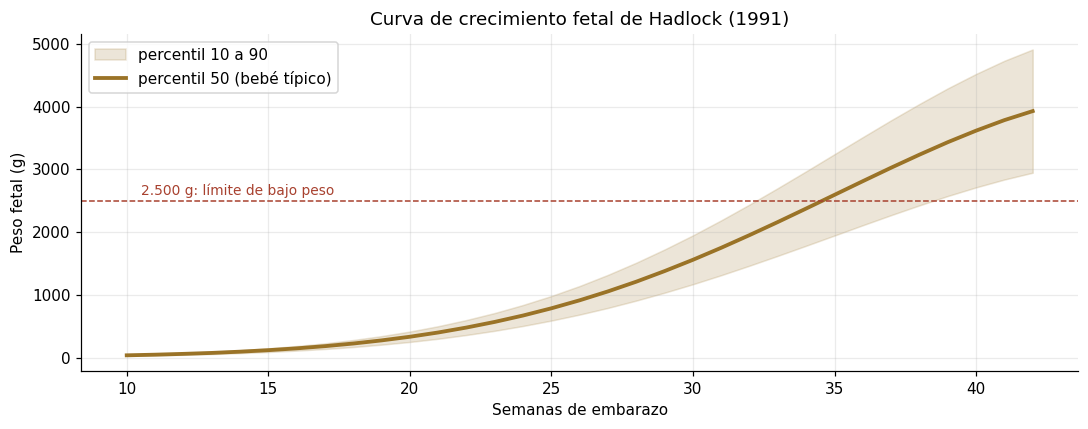

,Explicación
Qué es,La curva de crecimiento de Hadlock (1991): el peso de un bebé típico en cada semana de embarazo.
Qué pregunta responde,¿Cuánto debería pesar un bebé normal a esta edad?
Cómo se lee,La línea es el bebé típico; la banda va del percentil 10 al 90. Debajo de la banda = pequeño para su edad.
Resultado,A las 39 semanas el bebé típico pesa 3.435 g. Es el rival del modelo 1.


In [5]:
sem = sorted(HADLOCK_1991)
p10, p50, p90 = zip(*(HADLOCK_1991[s] for s in sem))
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(sem, p10, p90, color=OCRE, alpha=0.18, label="percentil 10 a 90")
ax.plot(sem, p50, color=OCRE, lw=2.5, label="percentil 50 (bebé típico)")
ax.axhline(2500, color=ROJO, ls="--", lw=1)
ax.text(10.5, 2600, "2.500 g: límite de bajo peso", color=ROJO, fontsize=9)
ax.set_title("Curva de crecimiento fetal de Hadlock (1991)")
ax.set_xlabel("Semanas de embarazo"); ax.set_ylabel("Peso fetal (g)")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

explicar("La curva de crecimiento de Hadlock (1991): el peso de un bebé típico en cada semana de embarazo.",
         "¿Cuánto debería pesar un bebé normal a esta edad?",
         "La línea es el bebé típico; la banda va del percentil 10 al 90. Debajo de la banda = pequeño para su edad.",
         f"A las 39 semanas el bebé típico pesa {miles(hadlock_curva(39))} g. Es el rival del modelo 1.")

### 1.4 Recursos que usa cada modelo

In [6]:
gpu = torch.cuda.get_device_properties(0) if torch.cuda.is_available() else None
tabla(pd.DataFrame([
    ["1 y 2 · Peso y bajo peso", "scikit-learn, pandas, numpy", "Procesador (CPU)", "Menos de 1 segundo",
     "1.000 filas en un Excel"],
    ["3 · Red: cabeza", "PyTorch + timm (EfficientNet-B0)",
     f"Tarjeta gráfica: {gpu.name} ({gpu.total_memory / 2**30:.0f} GB)" if gpu else "CPU (lento)",
     "Unos minutos", "999 imágenes, 126 MB"],
    ["4 · Red: plano", "PyTorch + timm (EfficientNet-B0)",
     f"Tarjeta gráfica: {gpu.name}" if gpu else "CPU (lento)", "Unos minutos", "12.400 imágenes, 2 GB"],
    ["Todos", "matplotlib, Pillow, openpyxl", f"{os.cpu_count()} núcleos de CPU", "—", "—"],
], columns=["Modelo", "Librerías", "Hardware", "Tiempo de entrenamiento", "Datos"]), rojo=["Hardware"], indice=False)

Modelo,Librerías,Hardware,Tiempo de entrenamiento,Datos
1 y 2 · Peso y bajo peso,"scikit-learn, pandas, numpy",Procesador (CPU),Menos de 1 segundo,1.000 filas en un Excel
3 · Red: cabeza,PyTorch + timm (EfficientNet-B0),Tarjeta gráfica: NVIDIA GeForce RTX 3090 (24 GB),Unos minutos,"999 imágenes, 126 MB"
4 · Red: plano,PyTorch + timm (EfficientNet-B0),Tarjeta gráfica: NVIDIA GeForce RTX 3090,Unos minutos,"12.400 imágenes, 2 GB"
Todos,"matplotlib, Pillow, openpyxl",16 núcleos de CPU,—,—


---
## Paso 2: Carga de datos

| Archivo | Qué tiene | Para qué modelos |
|---|---|---|
| `../modelo_peso_nacimiento/datos/nacimientos_reales_2014.xlsx` | 1.000 nacimientos reales (CDC 2014, OpenIntro) | 1 y 2 |
| `catalogo_imagenes.xlsx` | Una fila por imagen: dónde está y toda su información | 3 y 4 |

In [7]:
# Paso 2: Carga de datos
NACIMIENTOS = Path("../modelo_peso_nacimiento/datos/nacimientos_reales_2014.xlsx")
df = pd.read_excel(NACIMIENTOS, sheet_name="Nacimientos")
fuente_nac = pd.read_excel(NACIMIENTOS, sheet_name="Fuente")

CATALOGO = Path("catalogo_imagenes.xlsx")
hc = pd.read_excel(CATALOGO, sheet_name="HC18")
planos = pd.read_excel(CATALOGO, sheet_name="Planos")
fuentes_img = pd.read_excel(CATALOGO, sheet_name="Fuentes")

tabla(pd.DataFrame([
    ["Nacimientos (CDC 2014)", miles(len(df)), "—", "peso al nacer y bajo peso", "modelos 1 y 2"],
    ["HC18", miles(len(hc)), miles(hc["paciente"].nunique()), "circunferencia de la cabeza (mm)", "modelo 3"],
    ["FETAL_PLANES_DB", miles(len(planos)), miles(planos["paciente"].nunique()), "plano anatómico", "modelo 4"],
], columns=["Datos", "Filas", "Madres", "Respuesta correcta (etiqueta)", "Lo usa"]), rojo=["Respuesta correcta (etiqueta)"], indice=False)

Datos,Filas,Madres,Respuesta correcta (etiqueta),Lo usa
Nacimientos (CDC 2014),1.000,—,peso al nacer y bajo peso,modelos 1 y 2
HC18,999,779,circunferencia de la cabeza (mm),modelo 3
FETAL_PLANES_DB,12.400,1.792,plano anatómico,modelo 4


**Los primeros nacimientos:**

In [8]:
tabla(df.head(6), rojo=["peso_nacimiento_g", "bajo_peso"])

,id,semanas_gestacion,edad_madre,edad_padre,controles_prenatales,aumento_peso_madre_kg,fumadora,sexo_bebe,prematuro,casada,madre_blanca,peso_nacimiento_g,bajo_peso
0,1,37,34,34.000000,14.000000,12.700000,0.000000,masculino,0,1,1,3157,0
1,2,41,31,36.000000,12.000000,18.600000,0.000000,femenino,0,1,1,4019,0
2,3,37,36,37.000000,10.000000,12.700000,0.000000,femenino,0,1,0,3406,0
3,4,38,16,nan,nan,13.200000,0.000000,masculino,0,0,1,2808,0
4,5,36,31,32.000000,12.000000,21.800000,0.000000,femenino,1,1,1,3062,0
5,6,39,26,32.000000,14.000000,20.400000,0.000000,femenino,0,1,1,3035,0


**Las primeras imágenes de cada catálogo (cada fila apunta a su imagen en `ruta`):**

In [9]:
display(tabla(hc.head(4), rojo=["circunferencia_cefalica_mm"]))
tabla(planos.head(4), rojo=["plano"])

,archivo,ruta,paciente,imagen_de_la_paciente,tamano_pixel_mm,circunferencia_cefalica_mm,edad_gestacional_hadlock_sem,trimestre,particion
0,1_HC.png,imagenes/hc18/1_HC.png,HC18-P0001,1,0.069136,44.300000,11.400000,primero,validacion
1,2_HC.png,imagenes/hc18/2_HC.png,HC18-P0002,1,0.089659,56.810000,12.100000,primero,prueba
2,3_HC.png,imagenes/hc18/3_HC.png,HC18-P0003,1,0.062033,68.750000,12.800000,primero,entrenamiento
3,4_HC.png,imagenes/hc18/4_HC.png,HC18-P0004,1,0.091291,69.000000,12.800000,primero,entrenamiento


,archivo,ruta,paciente,plano,plano_original,subplano_cerebral,operador,ecografo,particion_oficial,particion
0,Patient00001_Plane1_1_of_15.png,imagenes/planos_fetales/Patient00001_Plane1_1_of_15.png,FP-P00001,otro,Other,Not A Brain,Other,Aloka,entrenamiento,entrenamiento
1,Patient00001_Plane1_2_of_15.png,imagenes/planos_fetales/Patient00001_Plane1_2_of_15.png,FP-P00001,otro,Other,Not A Brain,Other,Aloka,entrenamiento,entrenamiento
2,Patient00001_Plane1_3_of_15.png,imagenes/planos_fetales/Patient00001_Plane1_3_of_15.png,FP-P00001,otro,Other,Not A Brain,Other,Aloka,entrenamiento,entrenamiento
3,Patient00001_Plane1_4_of_15.png,imagenes/planos_fetales/Patient00001_Plane1_4_of_15.png,FP-P00001,otro,Other,Not A Brain,Other,Aloka,entrenamiento,entrenamiento


**De dónde vienen los datos:**

In [10]:
pd.set_option("display.max_colwidth", 120)
display(tabla(fuente_nac, indice=False))
tabla(fuentes_img, indice=False)

campo,detalle
Qué son,"Nacimientos reales, elegidos al azar"
Origen,"Registros de natalidad de Estados Unidos, año 2014 (CDC)"
Publicado por,"OpenIntro, conjunto de datos «births14», de uso libre para docencia"
Dirección,https://www.openintro.org/data/index.php?data=births14
Tamaño,1000 nacimientos
Qué NO tienen,Medidas de ecografía (no se puede aplicar Hadlock de 4 medidas)
Aviso,Población de EE. UU.: los resultados no se trasladan tal cual a Bolivia


dataset,estado,motivo,cita_y_licencia
HC18,USADO,999 imágenes de cabeza fetal con la circunferencia medida por ecografista,van den Heuvel TLA et al. PLoS ONE 2018;13(8):e0200412 · Zenodo 1327317 · CC BY 4.0
FETAL_PLANES_DB,USADO,12.400 imágenes de 6 planos anatómicos de 1.792 pacientes,Burgos-Artizzu XP et al. Sci Rep 2020;10:10200 · Zenodo 3904280 · CC BY 4.0
Large-Scale Fetal Head Biometry,NO USADO,Solo máscaras de segmentación; la medida habría que calcularla nosotros,CC BY 4.0
Fetal Brain Abnormalities (Roboflow),NO USADO,Trae varias copias aumentadas de la misma imagen: se colarían entre entrenamiento y prueba,Roboflow
Fetal Abdominal Structures,NO USADO,"Solo máscaras de segmentación, sin información numérica",—
fetal-ultrasound-brain,NO USADO,Es un subconjunto de FETAL_PLANES_DB (solo planos cerebrales),Kaggle
IUGC MICCAI 2024,NO USADO,Ecografía durante el parto: otro problema clínico,MICCAI 2024
Fetal Health Classification,NO USADO,"Solo tabla de cardiotocografía, sin imágenes",UCI / Kaggle
Agrupación por paciente en HC18,NOTA,"15_HC, 16_2HC, 17_3HC = 1.ª, 2.ª y 3.ª imagen de la misma madre; cada imagen se agrupa con el último _HC anterior",—


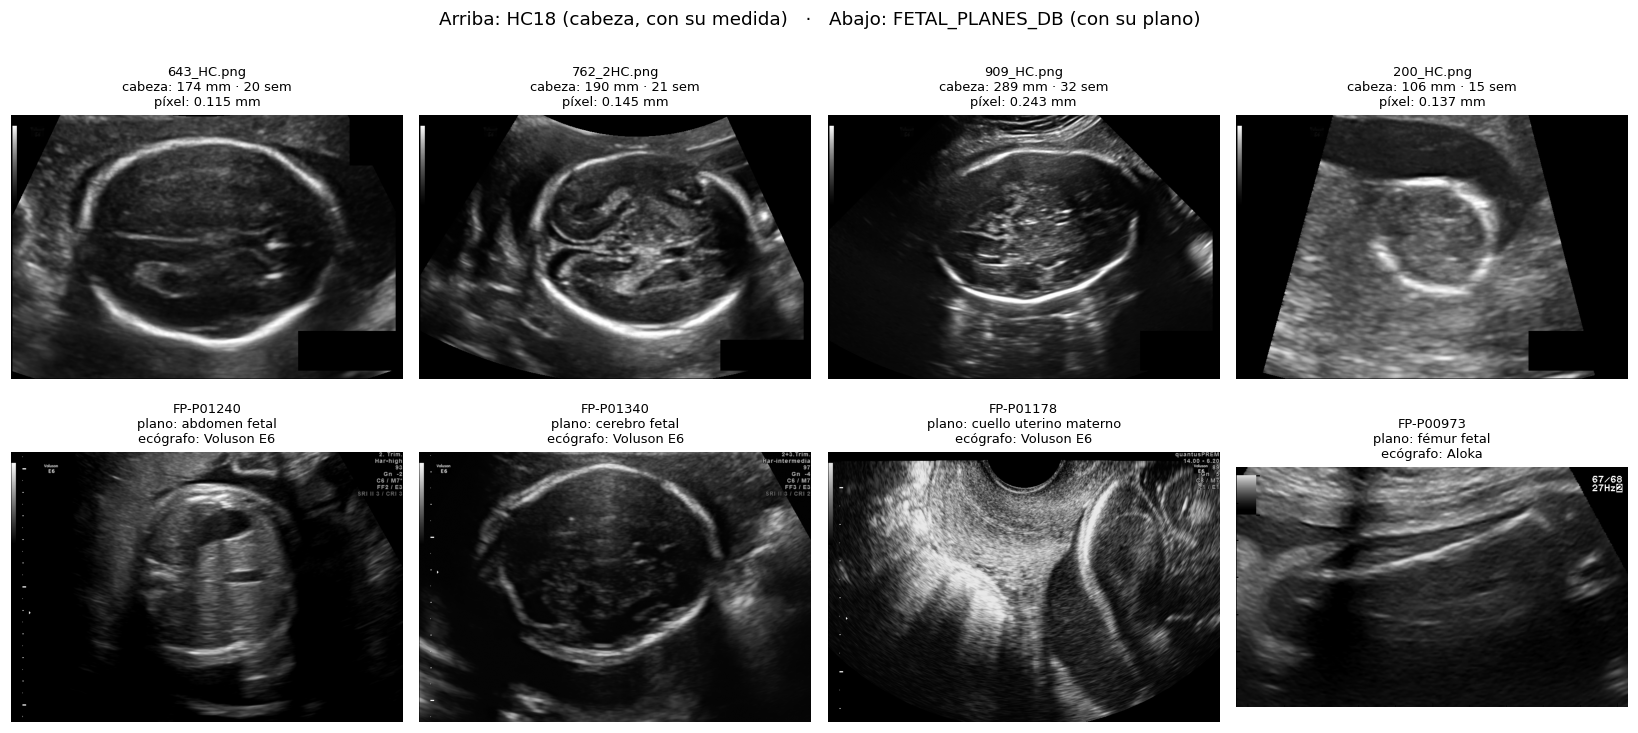

,Explicación
Qué es,Ocho ecografías reales con la información que viene con cada una.
Qué pregunta responde,¿Qué ve la red y qué respuesta correcta tiene cada imagen?
Cómo se lee,"Arriba, cabezas con la medida del ecografista y el tamaño del píxel. Abajo, planos con su nombre."
Resultado,"13.399 imágenes reales, todas con su anotación de experto."


In [11]:
fig, ejes = plt.subplots(2, 4, figsize=(15, 7))
for ax, (_, f) in zip(ejes[0], hc.sample(4, random_state=3).iterrows()):
    ax.imshow(Image.open(f["ruta"]), cmap="gray"); ax.axis("off")
    ax.set_title(f"{f['archivo']}\ncabeza: {f['circunferencia_cefalica_mm']:.0f} mm · "
                 f"{f['edad_gestacional_hadlock_sem']:.0f} sem\npíxel: {f['tamano_pixel_mm']:.3f} mm", fontsize=8.5)
for ax, (_, f) in zip(ejes[1], planos.groupby("plano").sample(1, random_state=2).head(4).iterrows()):
    ax.imshow(Image.open(f["ruta"]), cmap="gray"); ax.axis("off")
    ax.set_title(f"{f['paciente']}\nplano: {f['plano']}\necógrafo: {f['ecografo']}", fontsize=8.5)
fig.suptitle("Arriba: HC18 (cabeza, con su medida)   ·   Abajo: FETAL_PLANES_DB (con su plano)", y=1.0)
plt.tight_layout(); plt.show()

explicar("Ocho ecografías reales con la información que viene con cada una.",
         "¿Qué ve la red y qué respuesta correcta tiene cada imagen?",
         "Arriba, cabezas con la medida del ecografista y el tamaño del píxel. Abajo, planos con su nombre.",
         f"{miles(len(hc) + len(planos))} imágenes reales, todas con su anotación de experto.")

---
## Paso 3: Exploración de datos
### 3.1 Nacimientos: valores que faltan y estadísticas

In [12]:
faltan = df.isna().sum()
display(tabla(pd.DataFrame({"faltan": faltan, "% que falta": (faltan / len(df) * 100).round(1)})
              .query("faltan > 0"), rojo=["% que falta"]))
tabla(df[["semanas_gestacion", "edad_madre", "controles_prenatales", "aumento_peso_madre_kg",
          "peso_nacimiento_g"]].describe().T.round(1), rojo=["mean"])

,faltan,% que falta
edad_padre,114,11.400000
controles_prenatales,56,5.600000
aumento_peso_madre_kg,42,4.200000
fumadora,19,1.900000


,count,mean,std,min,25%,50%,75%,max
semanas_gestacion,1000.000000,38.700000,2.600000,21.000000,38.000000,39.000000,40.000000,46.000000
edad_madre,1000.000000,28.400000,5.800000,14.000000,24.000000,28.000000,33.000000,47.000000
controles_prenatales,944.000000,11.400000,4.100000,0.000000,9.000000,12.000000,14.000000,30.000000
aumento_peso_madre_kg,958.000000,13.800000,6.900000,0.000000,9.100000,13.600000,17.200000,44.500000
peso_nacimiento_g,1000.000000,3265.100000,592.700000,340.000000,2968.800000,3316.000000,3629.000000,4817.000000


Hay huecos (sobre todo la edad del padre). **No se borran filas**: en el paso 5 se
rellenan con la mediana **dentro del modelo**, usando solo los datos de entrenamiento.

### 3.2 Cuántos bebés nacen con bajo peso

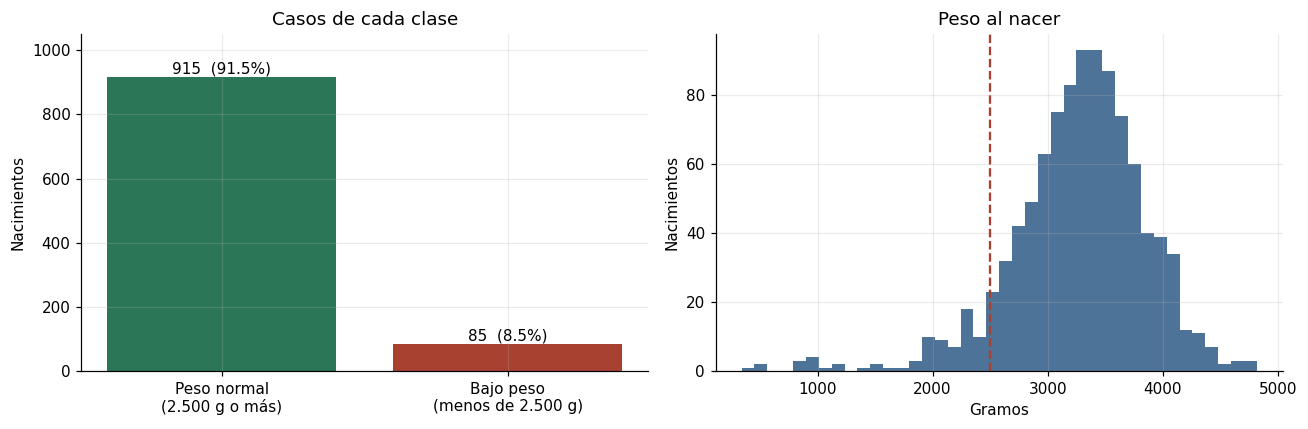

,Explicación
Qué es,Cuántos bebés hay de cada clase y cómo se reparte el peso al nacer.
Qué pregunta responde,¿Están equilibradas las clases que tiene que aprender el modelo 2?
Cómo se lee,"Barra roja = bajo peso. En el histograma, a la izquierda de la línea roja están los de bajo peso."
Resultado,"Solo 85 de 1000 (8.5%) nacen con bajo peso: un modelo que dijera siempre «normal» acertaría mucho sin detectar a ninguno. Por eso se mide la sensibilidad, no el acierto global."


In [13]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
n_bajo = int(df["bajo_peso"].sum())
a1.bar(["Peso normal\n(2.500 g o más)", "Bajo peso\n(menos de 2.500 g)"], [len(df) - n_bajo, n_bajo], color=[VERDE, ROJO])
for i, n in enumerate([len(df) - n_bajo, n_bajo]):
    a1.text(i, n + 12, f"{n}  ({n / len(df):.1%})", ha="center")
a1.set_title("Casos de cada clase"); a1.set_ylabel("Nacimientos"); a1.set_ylim(0, len(df) * 1.05)
a2.hist(df["peso_nacimiento_g"], bins=40, color=AZUL, alpha=0.85)
a2.axvline(2500, color=ROJO, ls="--")
a2.set_title("Peso al nacer"); a2.set_xlabel("Gramos"); a2.set_ylabel("Nacimientos")
plt.tight_layout(); plt.show()

explicar("Cuántos bebés hay de cada clase y cómo se reparte el peso al nacer.",
         "¿Están equilibradas las clases que tiene que aprender el modelo 2?",
         "Barra roja = bajo peso. En el histograma, a la izquierda de la línea roja están los de bajo peso.",
         f"Solo {n_bajo} de {len(df)} ({n_bajo / len(df):.1%}) nacen con bajo peso: un modelo que dijera siempre "
         "«normal» acertaría mucho sin detectar a ninguno. Por eso se mide la sensibilidad, no el acierto global.")

### 3.3 El peso real frente a la curva de Hadlock

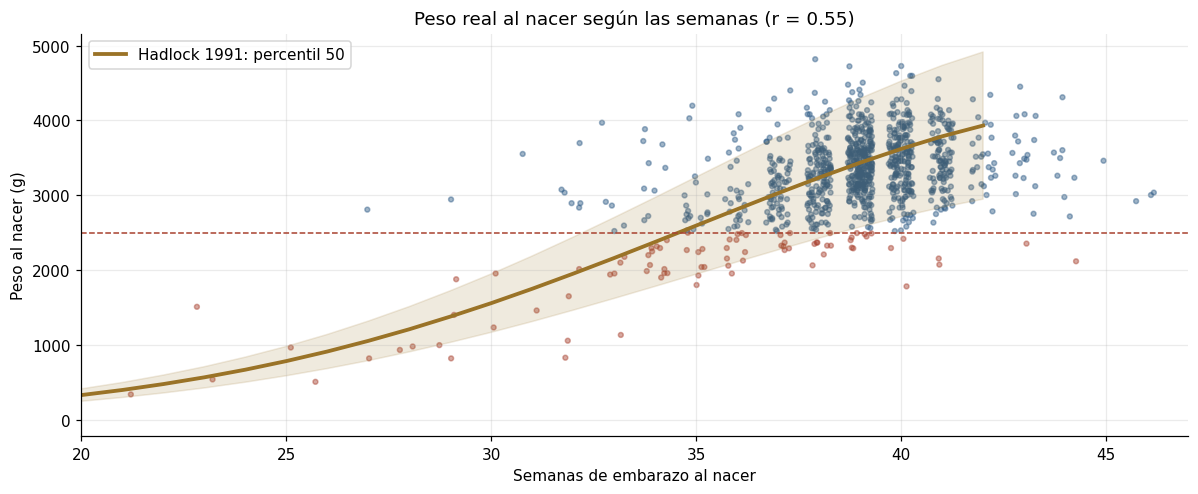

,Explicación
Qué es,Cada punto es un bebé real: sus semanas al nacer y su peso. La curva es Hadlock.
Qué pregunta responde,¿Hay una relación que el modelo pueda aprender?
Cómo se lee,"Rojo = bajo peso. Cuanto más pegados a la curva, más fácil predecir."
Resultado,"Correlación semanas-peso r = 0.55: fuerte, pero con mucha dispersión. Dos bebés de 39 semanas pueden pesar 2.600 y 4.300 g. Esto pone un techo a lo que puede acertar cualquier modelo."


In [14]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.scatter(df["semanas_gestacion"] + np.random.uniform(-0.3, 0.3, len(df)), df["peso_nacimiento_g"],
           s=10, alpha=0.45, c=np.where(df["bajo_peso"] == 1, ROJO, AZUL))
ax.fill_between(sem, p10, p90, color=OCRE, alpha=0.15)
ax.plot(sem, p50, color=OCRE, lw=2.5, label="Hadlock 1991: percentil 50")
ax.axhline(2500, color=ROJO, ls="--", lw=1)
r_sem = df["semanas_gestacion"].corr(df["peso_nacimiento_g"])
ax.set_title(f"Peso real al nacer según las semanas (r = {r_sem:.2f})")
ax.set_xlabel("Semanas de embarazo al nacer"); ax.set_ylabel("Peso al nacer (g)")
ax.set_xlim(20, 47); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

explicar("Cada punto es un bebé real: sus semanas al nacer y su peso. La curva es Hadlock.",
         "¿Hay una relación que el modelo pueda aprender?",
         "Rojo = bajo peso. Cuanto más pegados a la curva, más fácil predecir.",
         f"Correlación semanas-peso r = {r_sem:.2f}: fuerte, pero con mucha dispersión. Dos bebés de 39 semanas "
         "pueden pesar 2.600 y 4.300 g. Esto pone un techo a lo que puede acertar cualquier modelo.")

### 3.4 Qué se relaciona con el peso

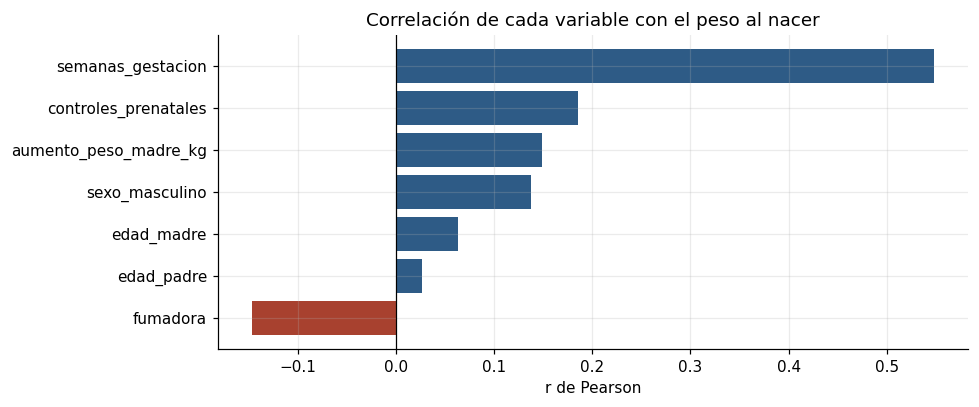

,Explicación
Qué es,La correlación de cada variable con el peso al nacer.
Qué pregunta responde,¿Qué datos ayudan a predecir el peso?
Cómo se lee,"Barra larga = relación fuerte. Azul sube el peso, rojo lo baja."
Resultado,"Las semanas dominan (r = 0.55); el resto aporta poco (la siguiente, controles_prenatales, r = 0.19)."


In [15]:
candidatas = ["semanas_gestacion", "edad_madre", "edad_padre", "controles_prenatales", "aumento_peso_madre_kg", "fumadora"]
aux = df[candidatas + ["peso_nacimiento_g"]].copy()
aux["sexo_masculino"] = (df["sexo_bebe"] == "masculino").astype(int)
corr = aux.corr()["peso_nacimiento_g"].drop("peso_nacimiento_g").sort_values()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(corr.index, corr.values, color=[AZUL if v > 0 else ROJO for v in corr.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Correlación de cada variable con el peso al nacer"); ax.set_xlabel("r de Pearson")
plt.tight_layout(); plt.show()

explicar("La correlación de cada variable con el peso al nacer.",
         "¿Qué datos ayudan a predecir el peso?",
         "Barra larga = relación fuerte. Azul sube el peso, rojo lo baja.",
         f"Las semanas dominan (r = {corr['semanas_gestacion']:.2f}); el resto aporta poco "
         f"(la siguiente, {corr.drop('semanas_gestacion').abs().idxmax()}, r = {corr.drop('semanas_gestacion').abs().max():.2f}).")

### 3.5 Imágenes: medidas de la cabeza y planos

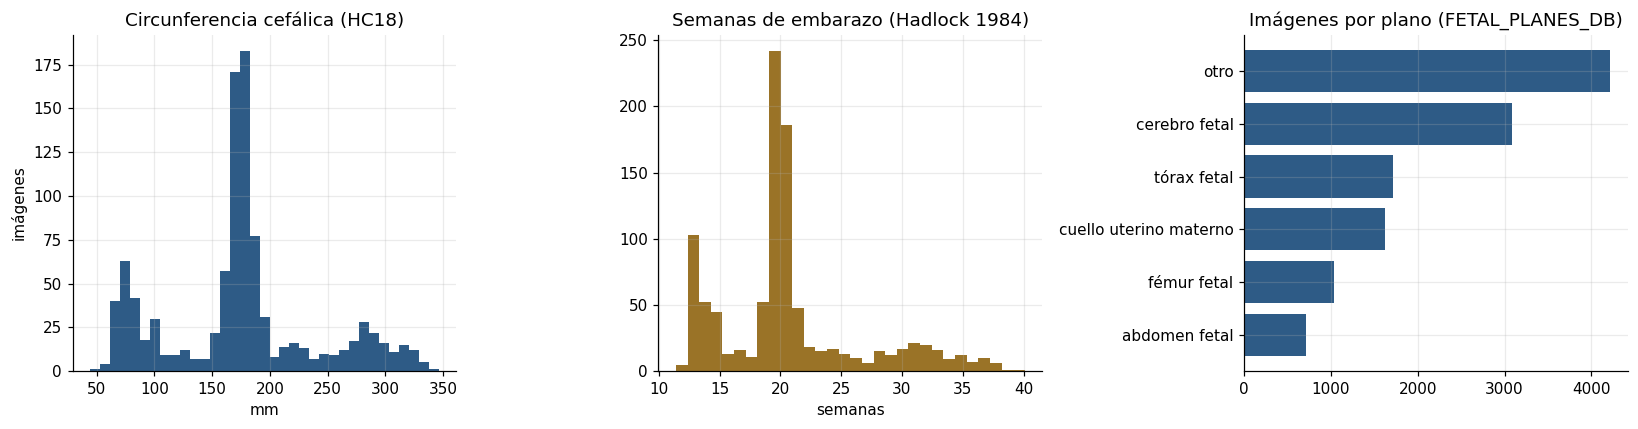

,Explicación
Qué es,"A la izquierda y al centro, las cabezas de HC18; a la derecha, cuántas imágenes hay de cada plano."
Qué pregunta responde,¿Qué rango tiene que cubrir la red 3 y están equilibradas las clases de la red 4?
Cómo se lee,Histogramas: cuántas imágenes hay de cada medida. Barras: imágenes por plano.
Resultado,Cabezas de 44 a 346 mm. En planos hay 5.9 veces más «otro» que «abdomen fetal»: en el paso 5 se compensa.


In [16]:
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 4))
a1.hist(hc["circunferencia_cefalica_mm"], bins=35, color=AZUL)
a1.set_title("Circunferencia cefálica (HC18)"); a1.set_xlabel("mm"); a1.set_ylabel("imágenes")
a2.hist(hc["edad_gestacional_hadlock_sem"], bins=30, color=OCRE)
a2.set_title("Semanas de embarazo (Hadlock 1984)"); a2.set_xlabel("semanas")
cuenta = planos["plano"].value_counts().sort_values()
a3.barh(cuenta.index, cuenta.values, color=AZUL)
a3.set_title("Imágenes por plano (FETAL_PLANES_DB)")
plt.tight_layout(); plt.show()

explicar("A la izquierda y al centro, las cabezas de HC18; a la derecha, cuántas imágenes hay de cada plano.",
         "¿Qué rango tiene que cubrir la red 3 y están equilibradas las clases de la red 4?",
         "Histogramas: cuántas imágenes hay de cada medida. Barras: imágenes por plano.",
         f"Cabezas de {hc['circunferencia_cefalica_mm'].min():.0f} a {hc['circunferencia_cefalica_mm'].max():.0f} mm. "
         f"En planos hay {cuenta.max() / cuenta.min():.1f} veces más «{cuenta.idxmax()}» que «{cuenta.idxmin()}»: "
         "en el paso 5 se compensa.")

### 3.6 ¿Hay madres repetidas entre entrenamiento y prueba?

In [17]:
filas = []
for nombre, d in [("HC18", hc), ("FETAL_PLANES_DB", planos)]:
    ent = set(d.loc[d["particion"] == "entrenamiento", "paciente"])
    val = set(d.loc[d["particion"] == "validacion", "paciente"])
    pru = set(d.loc[d["particion"] == "prueba", "paciente"])
    filas.append([nombre, len(ent), len(val), len(pru), len(ent & pru), len(val & pru), len(ent & val)])
solapes = pd.DataFrame(filas, columns=["Datos", "madres entrenamiento", "madres validación", "madres prueba",
                                       "entrenamiento Y prueba", "validación Y prueba", "entrenamiento Y validación"])
tabla(solapes, rojo=["entrenamiento Y prueba", "validación Y prueba", "entrenamiento Y validación"], indice=False)

Datos,madres entrenamiento,madres validación,madres prueba,entrenamiento Y prueba,validación Y prueba,entrenamiento Y validación
HC18,545,117,117,0,0,0
FETAL_PLANES_DB,807,89,896,0,0,0


**Cero en todas.** Es la comprobación más importante: si una madre estuviera en los dos
lados, la red la «reconocería» y los resultados saldrían inflados. Aquí no pasa.

---
## Paso 4: Definición de variables de entrada (X) y objetivo (y)

In [18]:
# Paso 4: Definición de variables de entrada (X) y objetivo (y)
df["sexo_masculino"] = (df["sexo_bebe"] == "masculino").astype(int)
ENTRADAS = ["semanas_gestacion", "edad_madre", "edad_padre", "controles_prenatales",
            "aumento_peso_madre_kg", "fumadora", "sexo_masculino"]
X = df[ENTRADAS]
y_peso = df["peso_nacimiento_g"]      # modelo 1: regresión
y_bajo = df["bajo_peso"]              # modelo 2: clasificación

X_ent, X_pru, yp_ent, yp_pru, yb_ent, yb_pru = train_test_split(
    X, y_peso, y_bajo, test_size=0.25, random_state=SEMILLA, stratify=y_bajo)

def cuenta(d, parte):
    return miles((d["particion"] == parte).sum())

tabla(pd.DataFrame([
    ["1. Peso al nacer", "7 variables de la madre y el embarazo", "peso_nacimiento_g (gramos)",
     f"{len(X_ent)} / — / {len(X_pru)}", "al azar, estratificado"],
    ["2. Bajo peso", "las mismas 7", "bajo_peso (0 = no, 1 = sí)",
     f"{len(X_ent)} / — / {len(X_pru)}", "al azar, estratificado"],
    ["3. Red: cabeza", "imagen 320×320 + tamaño del píxel", "circunferencia_cefalica_mm",
     f"{cuenta(hc, 'entrenamiento')} / {cuenta(hc, 'validacion')} / {cuenta(hc, 'prueba')}", "por madre"],
    ["4. Red: plano", "imagen 224×224", "plano (6 clases)",
     f"{cuenta(planos, 'entrenamiento')} / {cuenta(planos, 'validacion')} / {cuenta(planos, 'prueba')}", "por madre"],
], columns=["Modelo", "X (entrada)", "y (objetivo)", "entrenamiento / validación / prueba", "Cómo se separa"]),
      rojo=["y (objetivo)"], indice=False)

Modelo,X (entrada),y (objetivo),entrenamiento / validación / prueba,Cómo se separa
1. Peso al nacer,7 variables de la madre y el embarazo,peso_nacimiento_g (gramos),750 / — / 250,"al azar, estratificado"
2. Bajo peso,las mismas 7,"bajo_peso (0 = no, 1 = sí)",750 / — / 250,"al azar, estratificado"
3. Red: cabeza,imagen 320×320 + tamaño del píxel,circunferencia_cefalica_mm,709 / 144 / 146,por madre
4. Red: plano,imagen 224×224,plano (6 clases),6.471 / 658 / 5.271,por madre


**Columnas que NO entran en los modelos 1 y 2:** `peso_nacimiento_g` y `bajo_peso` (son
las respuestas), `prematuro` (se deduce de las semanas), `casada` y `madre_blanca`
(variables sociales de EE. UU. que no se trasladan a Bolivia).

**Por qué la red 3 necesita el tamaño del píxel.** La red ve píxeles y no sabe cuántos
milímetros mide cada uno: depende del zoom. Aprende **qué fracción de la imagen ocupa el
contorno** de la cabeza, y los milímetros salen multiplicando por el tamaño del píxel:

In [19]:
ejemplo = hc.iloc[0]
img, lado_mayor = cnn.cargar_cuadrada(Path(ejemplo["ruta"]), cnn.LADO_HC)
fraccion = ejemplo["circunferencia_cefalica_mm"] / (ejemplo["tamano_pixel_mm"] * lado_mayor)
tabla(pd.DataFrame([
    ["Imagen original", f"lado mayor {lado_mayor} px · píxel de {ejemplo['tamano_pixel_mm']:.4f} mm"],
    ["X (lo que ve la red)", f"imagen en gris de {img.shape[0]}×{img.shape[1]}, rellenada a cuadrado sin deformar"],
    ["y (lo que aprende)", f"el contorno mide {fraccion:.3f} veces el lado de la imagen"],
    ["De vuelta a mm", f"{fraccion:.3f} × {lado_mayor} × {ejemplo['tamano_pixel_mm']:.4f} = "
                       f"{fraccion * lado_mayor * ejemplo['tamano_pixel_mm']:.2f} mm (real: {ejemplo['circunferencia_cefalica_mm']} mm)"],
], columns=["", "Valor"]), rojo=["Valor"], indice=False)

,Valor
Imagen original,lado mayor 800 px · píxel de 0.0691 mm
X (lo que ve la red),"imagen en gris de 320×320, rellenada a cuadrado sin deformar"
y (lo que aprende),el contorno mide 0.801 veces el lado de la imagen
De vuelta a mm,0.801 × 800 × 0.0691 = 44.30 mm (real: 44.3 mm)


---
## Paso 5: Crear y entrenar los modelos
### 5.1 Modelo 1 · Regresión del peso al nacer

Tres algoritmos para compararlos. Cada uno va en un *pipeline* que rellena los huecos con
la mediana del entrenamiento y pone las variables en la misma escala. `.fit()` es el
momento en que el modelo aprende.

In [20]:
# Paso 5: Crear y entrenar los modelos
regresores = {
    "Ridge": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"),
                                   RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                                         random_state=SEMILLA, n_jobs=1)),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=8,
                                                       min_samples_leaf=20, l2_regularization=1.0,
                                                       random_state=SEMILLA),
}
tiempos = {}
for nombre, m in regresores.items():
    t = time.perf_counter(); m.fit(X_ent, yp_ent); tiempos[nombre] = (time.perf_counter() - t) * 1000
tabla(pd.DataFrame([
    ["Ridge", "Suma ponderada de las variables: cada una aporta unos gramos", f"{tiempos['Ridge']:.0f} ms"],
    ["Random Forest", "300 árboles de decisión que promedian su respuesta", f"{tiempos['Random Forest']:.0f} ms"],
    ["Gradient Boosting", "Árboles en cadena: cada uno corrige al anterior", f"{tiempos['Gradient Boosting']:.0f} ms"],
], columns=["Algoritmo", "Cómo funciona", "Entrenado en"]), indice=False)

Algoritmo,Cómo funciona,Entrenado en
Ridge,Suma ponderada de las variables: cada una aporta unos gramos,4 ms
Random Forest,300 árboles de decisión que promedian su respuesta,401 ms
Gradient Boosting,Árboles en cadena: cada uno corrige al anterior,1627 ms


### 5.2 Modelo 2 · Clasificación de bajo peso

Una **regresión logística** da una probabilidad de 0 a 1. Como solo el 8,5 % nace con bajo
peso, casi nadie llega al 50 %, y con ese umbral la alerta casi nunca saltaría. Se elige
el **umbral más alto que detecta al menos el 85 %** de los casos de bajo peso, calculado
**solo con los datos de entrenamiento** para que la prueba siga siendo honesta.

In [21]:
SENSIBILIDAD_OBJETIVO = 0.85
clasificador = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))


def elegir_umbral(X_e, y_e, objetivo=SENSIBILIDAD_OBJETIVO):
    # Umbral más alto que detecta al menos `objetivo` de los bajo peso, con
    # validación cruzada SOLO sobre el entrenamiento.
    prob = cross_val_predict(clone(clasificador), X_e, y_e, method="predict_proba",
                             cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA))[:, 1]
    positivos = np.sort(prob[np.asarray(y_e) == 1])
    return float(positivos[int(np.floor((1 - objetivo) * len(positivos)))])


umbral = elegir_umbral(X_ent, yb_ent)
clasificador.fit(X_ent, yb_ent)
coef = pd.DataFrame({
    "Ridge: gramos por desviación típica": regresores["Ridge"][-1].coef_.round(0).astype(int),
    "Logística: efecto sobre el riesgo de bajo peso": np.where(clasificador[-1].coef_[0] > 0, "lo SUBE", "lo BAJA"),
    "fuerza (coeficiente)": clasificador[-1].coef_[0].round(2),
}, index=ENTRADAS).sort_values("Ridge: gramos por desviación típica", key=abs, ascending=False)
g_semana = regresores["Ridge"][-1].coef_[0] / X_ent["semanas_gestacion"].std()
print(f"Umbral de alerta: {umbral:.3f} (alerta si la probabilidad supera {umbral:.1%})")
print(f"Cada semana más de embarazo suma unos {g_semana:.0f} g según Ridge")
tabla(coef, rojo=["Logística: efecto sobre el riesgo de bajo peso"])

Umbral de alerta: 0.048 (alerta si la probabilidad supera 4.8%)
Cada semana más de embarazo suma unos 124 g según Ridge


,Ridge: gramos por desviación típica,Logística: efecto sobre el riesgo de bajo peso,fuerza (coeficiente)
semanas_gestacion,326,lo BAJA,-1.280000
sexo_masculino,76,lo BAJA,-0.110000
aumento_peso_madre_kg,64,lo BAJA,-0.060000
fumadora,-53,lo SUBE,0.420000
edad_madre,39,lo SUBE,0.320000
controles_prenatales,31,lo BAJA,-0.150000
edad_padre,3,lo SUBE,0.090000


### 5.3 Modelos 3 y 4 · Las redes neuronales convolucionales

Las dos parten de **EfficientNet-B0 preentrenada**: una red que ya sabe ver bordes y formas
en millones de fotografías, y a la que solo hay que enseñarle ecografía. En cada época las
imágenes se **voltean, giran y cambian de brillo** al azar, y **se guarda la época que mejor
va en validación** (nunca en prueba: sería mirar las respuestas del examen).

`ENTRENAR = True` entrena de cero (unos minutos con GPU). Con `False` se cargan las redes ya
guardadas en `modelos/`, que son las que usa el sistema.

In [22]:
ENTRENAR = True

if ENTRENAR:
    t = time.time()
    red_hc, historia_hc, prueba_hc = cnn.entrenar_circunferencia(hc, epocas=40, registro=lambda *_: None)
    t_hc = time.time() - t
    t = time.time()
    red_planos, historia_planos, prueba_planos = cnn.entrenar_planos(planos, epocas=14, registro=lambda *_: None)
    t_planos = time.time() - t
else:
    red_hc, meta_hc = cnn.cargar("circunferencia_cefalica_hc18")
    red_planos, meta_planos = cnn.cargar("plano_anatomico_fetal_planes")
    historia_hc, historia_planos = meta_hc.get("historia", []), meta_planos.get("historia", [])
    prueba_hc, prueba_planos = cnn.evaluar_circunferencia(hc, red_hc), cnn.evaluar_planos(planos, red_planos)
    t_hc = t_planos = float("nan")

tabla(pd.DataFrame([
    ["3 · Red: cabeza", "EfficientNet-B0 → 1 salida (regresión)", "SmoothL1", 40,
     "volteos, giros, brillo (sin zoom: cambiaría la medida)", f"{t_hc:.0f} s"],
    ["4 · Red: plano", "EfficientNet-B0 → 6 salidas (clasificación)", "entropía cruzada con pesos por clase", 14,
     "volteos, giros, brillo y zoom", f"{t_planos:.0f} s"],
], columns=["Red", "Arquitectura", "Pérdida", "Épocas", "Aumento de datos", "Tiempo en GPU"]), indice=False)

Red,Arquitectura,Pérdida,Épocas,Aumento de datos,Tiempo en GPU
3 · Red: cabeza,EfficientNet-B0 → 1 salida (regresión),SmoothL1,40,"volteos, giros, brillo (sin zoom: cambiaría la medida)",79 s
4 · Red: plano,EfficientNet-B0 → 6 salidas (clasificación),entropía cruzada con pesos por clase,14,"volteos, giros, brillo y zoom",128 s


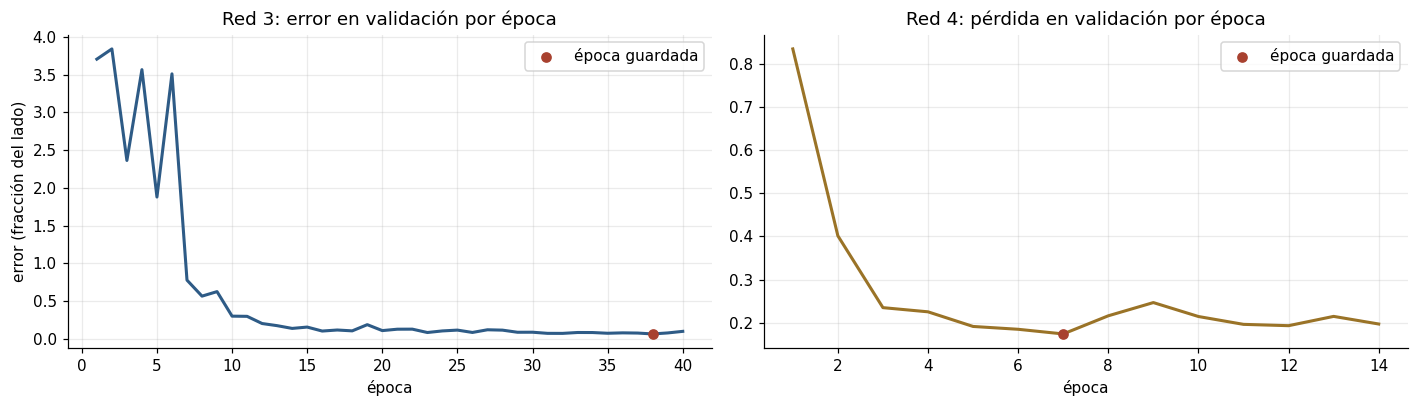

,Explicación
Qué es,Las curvas de aprendizaje: el error sobre imágenes de validación después de cada época.
Qué pregunta responde,"¿La red aprende, y cuándo deja de mejorar?"
Cómo se lee,"Cuanto más baja, mejor. El punto rojo es la época que se guarda."
Resultado,Red 3: mejor en la época 38 de 40. Red 4: mejor en la época 7 de 14.


In [23]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8))
h1, h2 = pd.DataFrame(historia_hc), pd.DataFrame(historia_planos)
if len(h1):
    a1.plot(h1["epoca"], h1["val"], color=AZUL, lw=2)
    a1.scatter(h1["val"].idxmin() + 1, h1["val"].min(), color=ROJO, zorder=5, label="época guardada")
    a1.legend()
a1.set_title("Red 3: error en validación por época"); a1.set_xlabel("época"); a1.set_ylabel("error (fracción del lado)")
if len(h2):
    a2.plot(h2["epoca"], h2["val"], color=OCRE, lw=2)
    a2.scatter(h2["val"].idxmin() + 1, h2["val"].min(), color=ROJO, zorder=5, label="época guardada")
    a2.legend()
a2.set_title("Red 4: pérdida en validación por época"); a2.set_xlabel("época")
plt.tight_layout(); plt.show()

explicar("Las curvas de aprendizaje: el error sobre imágenes de validación después de cada época.",
         "¿La red aprende, y cuándo deja de mejorar?",
         "Cuanto más baja, mejor. El punto rojo es la época que se guarda.",
         (f"Red 3: mejor en la época {h1['val'].idxmin() + 1} de {len(h1)}. "
          f"Red 4: mejor en la época {h2['val'].idxmin() + 1} de {len(h2)}.") if len(h1) and len(h2)
         else "Redes cargadas de disco: su curva se registró al entrenarlas.")

In [24]:
# Guardar las redes, con su curva de aprendizaje, para usarlas igual en el sistema
if ENTRENAR:
    cnn.guardar(red_hc, "circunferencia_cefalica_hc18", {
        "arquitectura": "efficientnet_b0", "lado": cnn.LADO_HC, "media": cnn.MEDIA, "desv": cnn.DESV,
        "salida": "fraccion del lado mayor de la imagen; mm = fraccion * lado_mayor_px * tamano_pixel_mm",
        "dataset": "HC18 (Zenodo 1327317, CC BY 4.0)", "entrenamiento": int((hc.particion == "entrenamiento").sum()),
        "historia": historia_hc})
    cnn.guardar(red_planos, "plano_anatomico_fetal_planes", {
        "arquitectura": "efficientnet_b0", "lado": cnn.LADO_PLANO, "media": cnn.MEDIA, "desv": cnn.DESV,
        "clases": cnn.PLANOS, "dataset": "FETAL_PLANES_DB (Zenodo 3904280, CC BY 4.0)",
        "historia": historia_planos})
    print("Guardadas en modelos/: circunferencia_cefalica_hc18.pth · plano_anatomico_fetal_planes.pth")

Guardadas en modelos/: circunferencia_cefalica_hc18.pth · plano_anatomico_fetal_planes.pth


---
## Paso 6: Hacer predicciones

Todos los modelos se aplican a datos de **prueba**: casos que no vieron al aprender.

### 6.1 Qué predice cada modelo

In [25]:
# Paso 6: Hacer predicciones
pred_peso = {n: m.predict(X_pru) for n, m in regresores.items()}
pred_peso["Curva de Hadlock"] = X_pru["semanas_gestacion"].map(hadlock_curva).to_numpy()
pred_peso["Mediana constante"] = np.full(len(yp_pru), yp_ent.median())
prob_bajo = clasificador.predict_proba(X_pru)[:, 1]
alerta = (prob_bajo >= umbral).astype(int)

tabla(pd.DataFrame({
    "semanas": X_pru["semanas_gestacion"].values,
    "peso real (g)": yp_pru.values,
    "modelo 1 · Ridge (g)": pred_peso["Ridge"].round(0).astype(int),
    "Hadlock (g)": pred_peso["Curva de Hadlock"],
    "modelo 2 · prob. bajo peso": np.round(prob_bajo, 2),
    "¿alerta?": np.where(alerta == 1, "SÍ", "no"),
    "¿era bajo peso?": np.where(yb_pru.values == 1, "SÍ", "no"),
}).head(12), rojo=["modelo 1 · Ridge (g)", "¿alerta?"], indice=False)

semanas,peso real (g),modelo 1 · Ridge (g),Hadlock (g),modelo 2 · prob. bajo peso,¿alerta?,¿era bajo peso?
39,3420,3516,3435,0.060000,SÍ,no
40,3343,3363,3619,0.020000,no,no
40,3769,3391,3619,0.030000,no,no
36,2667,2868,2813,0.120000,SÍ,no
43,3719,3918,3931,0.000000,no,no
41,2835,3766,3787,0.010000,no,no
36,2667,2987,2813,0.130000,SÍ,no
39,3289,3303,3435,0.030000,no,no
39,3384,3209,3435,0.170000,SÍ,no
44,2717,3825,3931,0.010000,no,no


### 6.2 Un caso de consulta: la misma madre, según cuándo nazca el bebé

In [26]:
consulta = pd.DataFrame([{"semanas_gestacion": s, "edad_madre": 24, "edad_padre": 26, "controles_prenatales": 8,
                          "aumento_peso_madre_kg": 9.0, "fumadora": 1, "sexo_masculino": 0}
                         for s in [33, 35, 37, 39, 41]])[ENTRADAS]
p = clasificador.predict_proba(consulta)[:, 1]
tabla(pd.DataFrame({
    "si nace a las": [f"{s} semanas" for s in consulta["semanas_gestacion"]],
    "modelo 1 · Ridge (g)": regresores["Ridge"].predict(consulta).round(0).astype(int),
    "Hadlock (g)": consulta["semanas_gestacion"].map(hadlock_curva),
    "modelo 2 · prob. bajo peso": [f"{v:.0%}" for v in p],
    "alerta": np.where(p >= umbral, "SÍ", "no"),
}), rojo=["alerta"], indice=False)

si nace a las,modelo 1 · Ridge (g),Hadlock (g),modelo 2 · prob. bajo peso,alerta
33 semanas,2231,2162,68%,SÍ
35 semanas,2479,2595,44%,SÍ
37 semanas,2728,3028,23%,SÍ
39 semanas,2976,3435,10%,SÍ
41 semanas,3225,3787,4%,no


### 6.3 Red 3: la medida de la cabeza, imagen por imagen

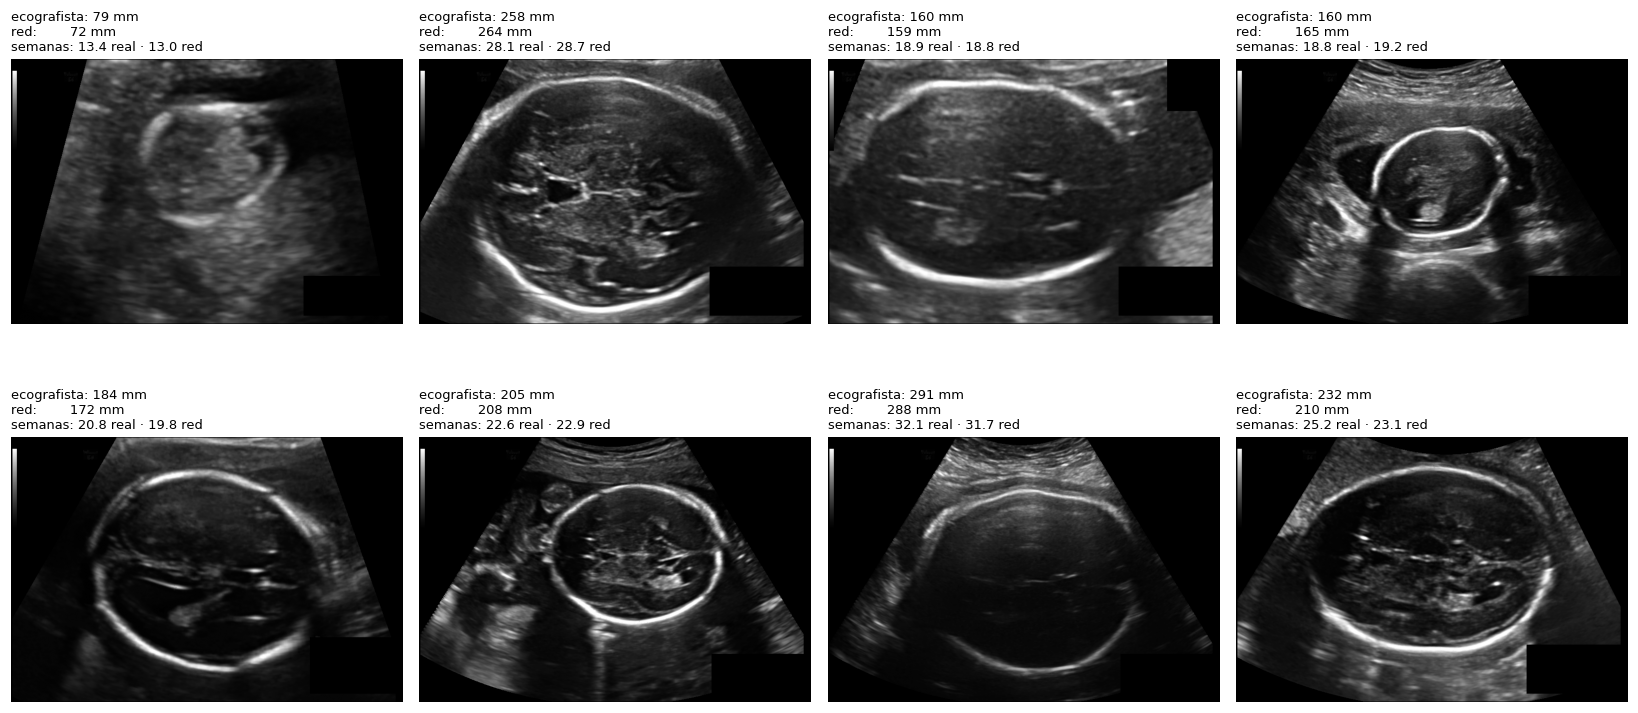

,Explicación
Qué es,Ocho cabezas de prueba con la medida del ecografista y la de la red.
Qué pregunta responde,"¿Cuánto se parece la medida de la red a la del profesional, imagen por imagen?"
Cómo se lee,"Arriba de cada imagen: medida real, medida de la red y semanas de embarazo de cada una."
Resultado,Elegidas al azar. Error medio en las 146 de prueba: 7.0 mm (ver paso 7.4).


In [27]:
prueba_hc["semanas_real"] = semanas_por_hc(prueba_hc["circunferencia_cefalica_mm"]).round(1)
prueba_hc["semanas_red"] = semanas_por_hc(prueba_hc["hc_predicha_mm"]).round(1)
fig, ejes = plt.subplots(2, 4, figsize=(15, 7.5))
for ax, (_, f) in zip(ejes.ravel(), prueba_hc.sample(8, random_state=7).iterrows()):
    ax.imshow(Image.open(f["ruta"]), cmap="gray"); ax.axis("off")
    ax.set_title(f"ecografista: {f['circunferencia_cefalica_mm']:.0f} mm\nred:        {f['hc_predicha_mm']:.0f} mm\n"
                 f"semanas: {f['semanas_real']:.1f} real · {f['semanas_red']:.1f} red", fontsize=8.5, loc="left")
plt.tight_layout(); plt.show()

explicar("Ocho cabezas de prueba con la medida del ecografista y la de la red.",
         "¿Cuánto se parece la medida de la red a la del profesional, imagen por imagen?",
         "Arriba de cada imagen: medida real, medida de la red y semanas de embarazo de cada una.",
         f"Elegidas al azar. Error medio en las {len(prueba_hc)} de prueba: "
         f"{prueba_hc['error_mm'].abs().mean():.1f} mm (ver paso 7.4).")

In [28]:
tabla(prueba_hc[["archivo", "circunferencia_cefalica_mm", "hc_predicha_mm", "error_mm", "semanas_real", "semanas_red"]]
      .head(10), rojo=["hc_predicha_mm", "error_mm"], indice=False)

archivo,circunferencia_cefalica_mm,hc_predicha_mm,error_mm,semanas_real,semanas_red
2_HC.png,56.810000,57.160000,0.350000,12.100000,12.100000
5_HC.png,59.810000,60.240000,0.430000,12.300000,12.300000
7_HC.png,67.840000,73.450000,5.610000,12.700000,13.000000
8_2HC.png,62.800000,74.760000,11.960000,12.400000,13.100000
33_HC.png,70.510000,67.730000,-2.780000,12.900000,12.700000
34_2HC.png,75.200000,63.850000,-11.350000,13.100000,12.500000
51_HC.png,68.700000,79.340000,10.640000,12.800000,13.400000
53_HC.png,69.840000,65.270000,-4.570000,12.800000,12.600000
64_HC.png,71.910000,76.100000,4.190000,13.000000,13.200000
91_HC.png,76.290000,70.260000,-6.030000,13.200000,12.900000


### 6.4 Red 4: el plano, imagen por imagen (aciertos y errores)

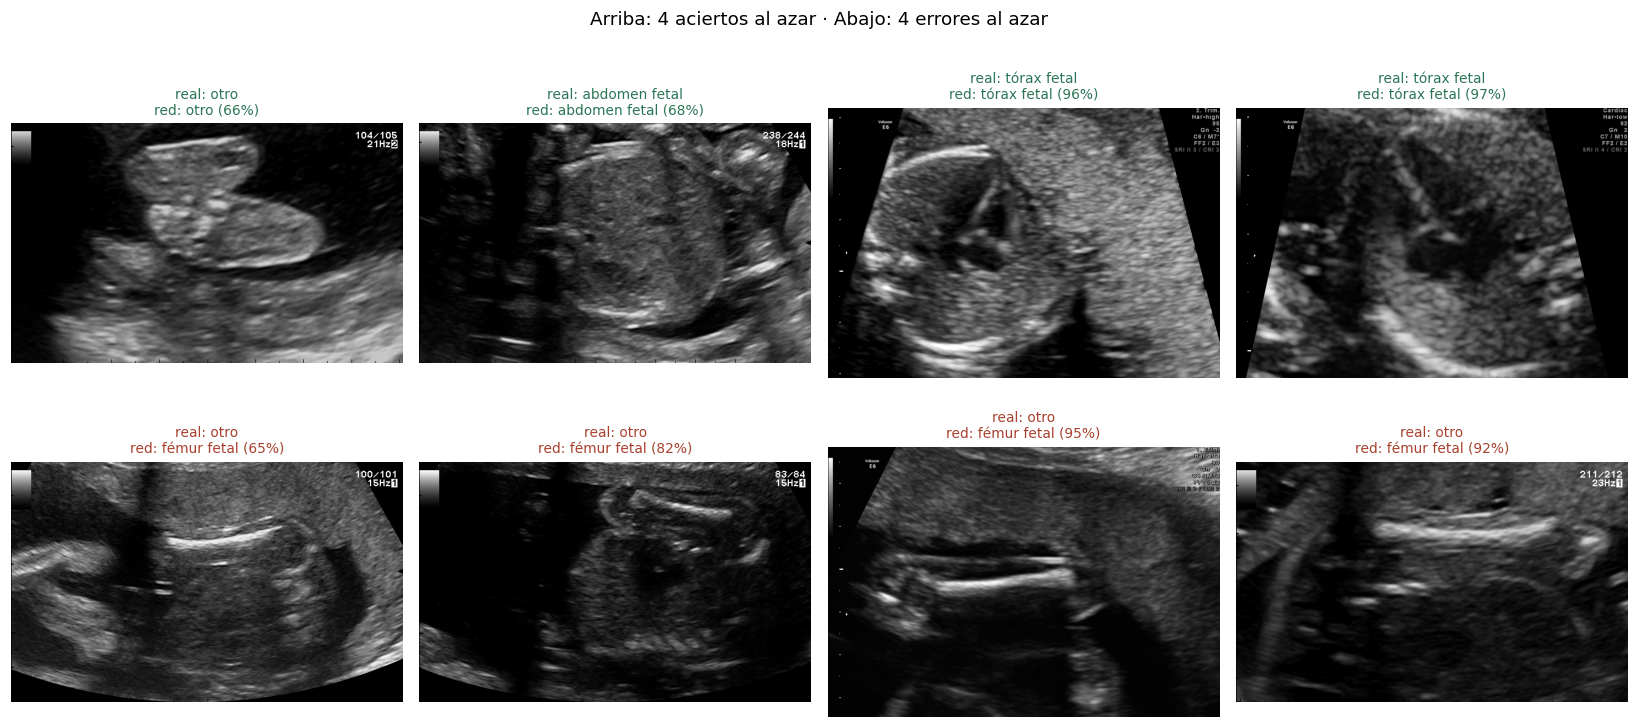

,Explicación
Qué es,"Ocho imágenes de prueba: cuatro aciertos y cuatro errores, elegidos al azar."
Qué pregunta responde,¿Cómo se equivoca la red cuando se equivoca?
Cómo se lee,"Verde = acierto, rojo = error. Entre paréntesis, la seguridad de la red."
Resultado,"Se muestran errores a propósito: suelen ser imágenes «otro» que se parecen a un plano, y a menudo con menos seguridad. El sistema avisa cuando la seguridad baja del 70 %."


In [29]:
aciertos = prueba_planos[prueba_planos["plano"] == prueba_planos["plano_predicho"]].sample(4, random_state=11)
errores = prueba_planos[prueba_planos["plano"] != prueba_planos["plano_predicho"]].sample(4, random_state=11)
fig, ejes = plt.subplots(2, 4, figsize=(15, 7))
for ax, (_, f) in zip(ejes.ravel(), pd.concat([aciertos, errores]).iterrows()):
    ax.imshow(Image.open(f["ruta"]), cmap="gray"); ax.axis("off")
    ok = f["plano"] == f["plano_predicho"]
    ax.set_title(f"real: {f['plano']}\nred: {f['plano_predicho']} ({f['prob_' + f['plano_predicho']]:.0%})",
                 fontsize=9, color=VERDE if ok else ROJO)
fig.suptitle("Arriba: 4 aciertos al azar · Abajo: 4 errores al azar", y=1.0)
plt.tight_layout(); plt.show()

explicar("Ocho imágenes de prueba: cuatro aciertos y cuatro errores, elegidos al azar.",
         "¿Cómo se equivoca la red cuando se equivoca?",
         "Verde = acierto, rojo = error. Entre paréntesis, la seguridad de la red.",
         "Se muestran errores a propósito: suelen ser imágenes «otro» que se parecen a un plano, y a menudo con "
         "menos seguridad. El sistema avisa cuando la seguridad baja del 70 %.")

### 6.5 Cómo se usa la predicción con la red neuronal

En el sistema, las predicciones se encadenan así:

```
ecografía ──► red 4: ¿qué plano es? ──► si es cabeza ──► red 3: ¿cuánto mide? ──► Hadlock 1984 ──► semanas de embarazo
                                                                                                      │
datos de la madre ──────────────────────────────────────────────────────────────► modelo 1 y 2 ◄───┘ (semana prevista del parto)
                                                                                    │
                                                                         peso previsto + alerta de bajo peso
```

La red fecha el embarazo; con esa fecha se sabe cuándo nacerá a término, y los modelos 1 y 2
dicen cuánto pesará y si hay riesgo. La celda de abajo lo hace con una imagen real de prueba.

In [30]:
caso = prueba_hc.iloc[(prueba_hc["error_mm"].abs() - prueba_hc["error_mm"].abs().median()).abs().argmin()]
red_planos.eval()
x, _ = cnn.cargar_cuadrada(Path(caso["ruta"]), cnn.LADO_PLANO)
probs = cnn.predecir(red_planos, x[None], False)[0]
plano_caso = cnn.PLANOS[int(probs.argmax())]
semanas_hoy = float(semanas_por_hc(caso["hc_predicha_mm"]))
madre = pd.DataFrame([{"semanas_gestacion": 39, "edad_madre": 24, "edad_padre": 26, "controles_prenatales": 8,
                       "aumento_peso_madre_kg": 12.0, "fumadora": 0, "sexo_masculino": 0}])[ENTRADAS]
peso_39 = regresores["Ridge"].predict(madre)[0]
riesgo_39 = clasificador.predict_proba(madre)[0, 1]

tabla(pd.DataFrame([
    ["1", "Red 4 (plano)", caso["archivo"], f"{plano_caso} ({probs.max():.0%})"],
    ["2", "Red 3 (cabeza)", "la misma imagen + píxel de " + f"{caso['tamano_pixel_mm']:.4f} mm",
     f"{caso['hc_predicha_mm']:.1f} mm (ecografista: {caso['circunferencia_cefalica_mm']:.1f} mm)"],
    ["3", "Hadlock 1984", f"{caso['hc_predicha_mm']:.1f} mm", f"{semanas_hoy:.1f} semanas de embarazo hoy"],
    ["4", "Fecha prevista", f"{semanas_hoy:.1f} semanas", f"nacería a término (39 sem) en unas {39 - semanas_hoy:.0f} semanas"],
    ["5", "Modelo 1 (peso)", "madre de 24 años, no fuma, parto a las 39 semanas", f"{peso_39:,.0f} g".replace(",", ".")],
    ["6", "Modelo 2 (bajo peso)", "los mismos datos", f"probabilidad {riesgo_39:.1%} → alerta: {'SÍ' if riesgo_39 >= umbral else 'no'}"],
], columns=["Paso", "Modelo", "Entrada", "Predicción"]), rojo=["Predicción"], indice=False)

Paso,Modelo,Entrada,Predicción
1,Red 4 (plano),770_HC.png,cerebro fetal (94%)
2,Red 3 (cabeza),la misma imagen + píxel de 0.1440 mm,190.6 mm (ecografista: 196.0 mm)
3,Hadlock 1984,190.6 mm,21.3 semanas de embarazo hoy
4,Fecha prevista,21.3 semanas,nacería a término (39 sem) en unas 18 semanas
5,Modelo 1 (peso),"madre de 24 años, no fuma, parto a las 39 semanas",3.173 g
6,Modelo 2 (bajo peso),los mismos datos,probabilidad 2.7% → alerta: no


**Advertencia honesta:** los datos de la madre del paso 5 son un ejemplo. La imagen es de
HC18 y los nacimientos son de EE. UU.: no es la misma paciente. El encadenamiento muestra
**cómo** se usan juntas las predicciones en el sistema, no un caso clínico real.

---
## Paso 7: Evaluar los modelos
### 7.1 Las métricas, en palabras

In [31]:
# Paso 7: Evaluar los modelos
tabla(pd.DataFrame([
    ["R²", "Regresión", "Qué parte de la variación explica el modelo", "¿Cuánto de lo que cambia el peso (o la medida) entiende?", "cerca de 1"],
    ["MAE", "Regresión", "Error medio absoluto", "¿Por cuánto se equivoca de media?", "bajo"],
    ["RMSE", "Regresión", "Error cuadrático medio: castiga más los errores grandes", "¿Hay errores muy grandes?", "bajo"],
    ["Dentro de ±15 %", "Regresión", "Casos con error menor del 15 %", "¿Cuántas veces acierta dentro del margen de Hadlock?", "alto"],
    ["Verdaderos positivos (VP)", "Clasificación", "Casos positivos que el modelo SÍ detectó", "¿A cuántos detectó?", "alto"],
    ["Falsos negativos (FN)", "Clasificación", "Casos positivos que se le escaparon", "¿A cuántos no vio? (el error más grave)", "bajo"],
    ["Falsos positivos (FP)", "Clasificación", "Alertas en casos que no lo eran", "¿Cuántas falsas alarmas da?", "bajo"],
    ["Sensibilidad", "Clasificación", "VP ÷ (VP + FN)", "De los que lo tenían, ¿qué parte detecta?", "alta"],
    ["Especificidad", "Clasificación", "VN ÷ (VN + FP)", "De los sanos, ¿qué parte deja tranquilos?", "alta"],
    ["Precisión", "Clasificación", "VP ÷ (VP + FP)", "Cuando da la alerta, ¿cuántas veces tiene razón?", "alta"],
    ["F1", "Clasificación", "Equilibrio entre sensibilidad y precisión", "¿Detecta sin llenarse de falsas alarmas?", "alta"],
    ["AUC (ROC)", "Clasificación", "Área bajo la curva ROC", "¿Separa bien las clases? 1 = perfecto, 0,5 = azar", "cerca de 1"],
    ["Kappa de Cohen", "Clasificación", "Acierto descontando el que se lograría por azar", "¿Acierta más que adivinando?", "cerca de 1"],
], columns=["Métrica", "Tipo", "Qué es", "Qué pregunta responde", "Buena si es"]), rojo=["Qué pregunta responde"], indice=False)

Métrica,Tipo,Qué es,Qué pregunta responde,Buena si es
R²,Regresión,Qué parte de la variación explica el modelo,¿Cuánto de lo que cambia el peso (o la medida) entiende?,cerca de 1
MAE,Regresión,Error medio absoluto,¿Por cuánto se equivoca de media?,bajo
RMSE,Regresión,Error cuadrático medio: castiga más los errores grandes,¿Hay errores muy grandes?,bajo
Dentro de ±15 %,Regresión,Casos con error menor del 15 %,¿Cuántas veces acierta dentro del margen de Hadlock?,alto
Verdaderos positivos (VP),Clasificación,Casos positivos que el modelo SÍ detectó,¿A cuántos detectó?,alto
Falsos negativos (FN),Clasificación,Casos positivos que se le escaparon,¿A cuántos no vio? (el error más grave),bajo
Falsos positivos (FP),Clasificación,Alertas en casos que no lo eran,¿Cuántas falsas alarmas da?,bajo
Sensibilidad,Clasificación,VP ÷ (VP + FN),"De los que lo tenían, ¿qué parte detecta?",alta
Especificidad,Clasificación,VN ÷ (VN + FP),"De los sanos, ¿qué parte deja tranquilos?",alta
Precisión,Clasificación,VP ÷ (VP + FP),"Cuando da la alerta, ¿cuántas veces tiene razón?",alta


### 7.2 Modelo 1 · Regresión del peso al nacer

In [32]:
def metricas_reg(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    return {"MAE (g)": mean_absolute_error(real, pred), "RMSE (g)": np.sqrt(mean_squared_error(real, pred)),
            "R²": r2_score(real, pred), "error % medio": np.mean(np.abs(pred - real) / real),
            "dentro ±15 %": np.mean(np.abs(pred - real) / real <= 0.15)}

reg = pd.DataFrame({n: metricas_reg(yp_pru, p) for n, p in pred_peso.items()}).T.sort_values("MAE (g)")
tabla(reg, rojo=["R²"], formato={"MAE (g)": "{:.0f}", "RMSE (g)": "{:.0f}", "R²": "{:.3f}",
                                  "error % medio": "{:.1%}", "dentro ±15 %": "{:.1%}"})

,MAE (g),RMSE (g),R²,error % medio,dentro ±15 %
Random Forest,370,474,0.322,12.4%,69.6%
Ridge,379,486,0.288,13.1%,70.8%
Gradient Boosting,384,496,0.260,13.3%,68.4%
Curva de Hadlock,399,519,0.190,13.2%,66.8%
Mediana constante,430,576,-0.001,16.7%,67.6%


**¿La diferencia con Hadlock es real?** Se repite 5 veces rotando la parte de prueba
(validación cruzada) y se compara partición a partición. Solo es mejora si gana en las 5 y
por más de dos errores estándar. También se da el **R² de cada partición**.

In [33]:
kf = KFold(5, shuffle=True, random_state=SEMILLA)
mae_cv = {n: [] for n in list(regresores) + ["Curva de Hadlock"]}
r2_cv = {n: [] for n in mae_cv}
hadlock_total = df["semanas_gestacion"].map(hadlock_curva)
for e, p in kf.split(X):
    for n, m in regresores.items():
        pr = clone(m).fit(X.iloc[e], y_peso.iloc[e]).predict(X.iloc[p])
        mae_cv[n].append(mean_absolute_error(y_peso.iloc[p], pr)); r2_cv[n].append(r2_score(y_peso.iloc[p], pr))
    mae_cv["Curva de Hadlock"].append(mean_absolute_error(y_peso.iloc[p], hadlock_total.iloc[p]))
    r2_cv["Curva de Hadlock"].append(r2_score(y_peso.iloc[p], hadlock_total.iloc[p]))

cv = pd.DataFrame(mae_cv).T
cv.columns = [f"partición {i + 1}" for i in range(5)]
cv["MAE medio (g)"] = cv.mean(axis=1)
cv["desviación (g)"] = cv.iloc[:, :5].std(axis=1)
cv["R² medio"] = [np.mean(r2_cv[n]) for n in cv.index]
cv["R² mín – máx"] = [f"{min(r2_cv[n]):.2f} – {max(r2_cv[n]):.2f}" for n in cv.index]
mejor = cv.drop("Curva de Hadlock")["MAE medio (g)"].idxmin()
dif = np.array(mae_cv["Curva de Hadlock"]) - np.array(mae_cv[mejor])
gana = int((dif > 0).sum())
mejora_real = dif.mean() > 2 * dif.std(ddof=1) / np.sqrt(5) and gana == 5
veredicto = "MEJORA REAL" if mejora_real else ("EMPATE" if dif.mean() > 0 else "PIERDE")
print(f"Mejor modelo: {mejor} · mejora sobre Hadlock {dif.mean():+.0f} g · gana en {gana} de 5 → {veredicto}")
tabla(cv.sort_values("MAE medio (g)"), rojo=["MAE medio (g)", "R² medio"],
      formato={c: "{:.0f}" for c in cv.columns[:7]} | {"R² medio": "{:.3f}"})

Mejor modelo: Random Forest · mejora sobre Hadlock +21 g · gana en 5 de 5 → MEJORA REAL


,partición 1,partición 2,partición 3,partición 4,partición 5,MAE medio (g),desviación (g),R² medio,R² mín – máx
Random Forest,369,352,361,354,432,374,33,0.312,0.12 – 0.42
Ridge,368,354,352,366,452,378,42,0.325,0.19 – 0.38
Gradient Boosting,368,369,375,362,442,384,33,0.278,0.03 – 0.39
Curva de Hadlock,379,371,399,386,441,395,28,0.228,0.04 – 0.35


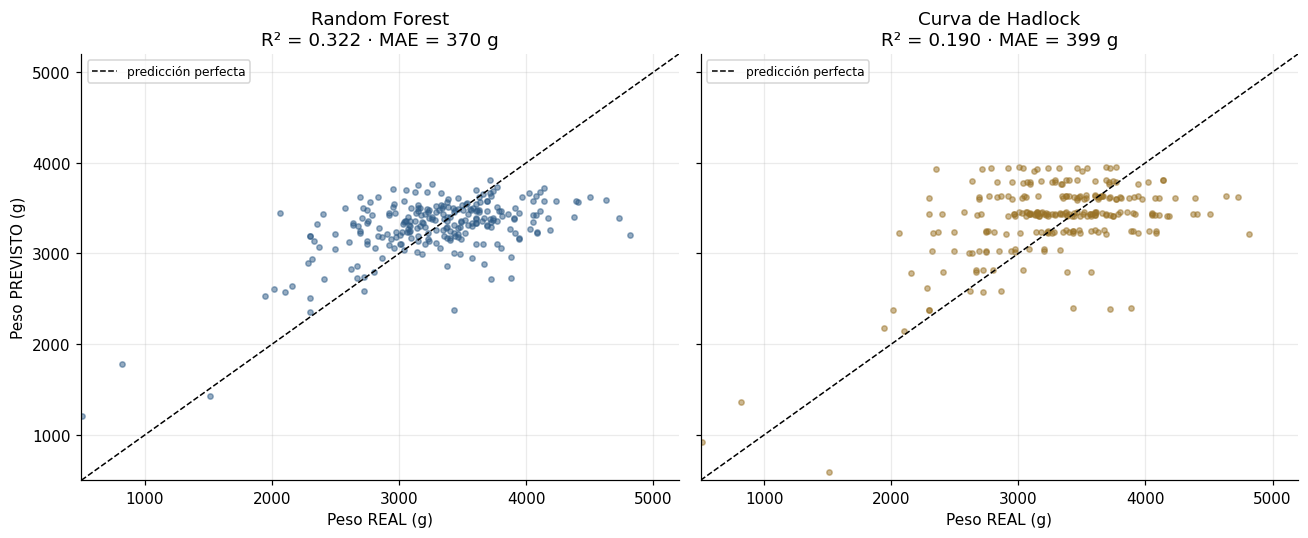

,Explicación
Qué es,"Peso real frente a peso previsto, para el mejor modelo y para la curva de Hadlock."
Qué pregunta responde,¿Cuánto se acerca la predicción al peso real? (esto es lo que mide el R²)
Cómo se lee,"Si el modelo fuera perfecto, todos los puntos caerían sobre la diagonal."
Resultado,"R² REAL del Random Forest en prueba: 0.322. Es bajo, y es honesto: sin medidas de ecografía, solo con semanas y datos de la madre, no se puede explicar más del peso. Frente a Hadlock: MEJORA REAL."


In [34]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, n, c in [(ejes[0], mejor, AZUL), (ejes[1], "Curva de Hadlock", OCRE)]:
    pp = pred_peso[n]
    ax.scatter(yp_pru, pp + (np.random.uniform(-25, 25, len(pp)) if n == "Curva de Hadlock" else 0), s=12, alpha=0.5, color=c)
    lim = [500, 5200]
    ax.plot(lim, lim, "k--", lw=1, label="predicción perfecta")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{n}\nR² = {r2_score(yp_pru, pp):.3f} · MAE = {mean_absolute_error(yp_pru, pp):.0f} g")
    ax.set_xlabel("Peso REAL (g)"); ax.legend(loc="upper left", fontsize=8)
ejes[0].set_ylabel("Peso PREVISTO (g)")
plt.tight_layout(); plt.show()

explicar("Peso real frente a peso previsto, para el mejor modelo y para la curva de Hadlock.",
         "¿Cuánto se acerca la predicción al peso real? (esto es lo que mide el R²)",
         "Si el modelo fuera perfecto, todos los puntos caerían sobre la diagonal.",
         f"R² REAL del {mejor} en prueba: {r2_score(yp_pru, pred_peso[mejor]):.3f}. Es bajo, y es honesto: sin "
         "medidas de ecografía, solo con semanas y datos de la madre, no se puede explicar más del peso. "
         f"Frente a Hadlock: {veredicto}.")

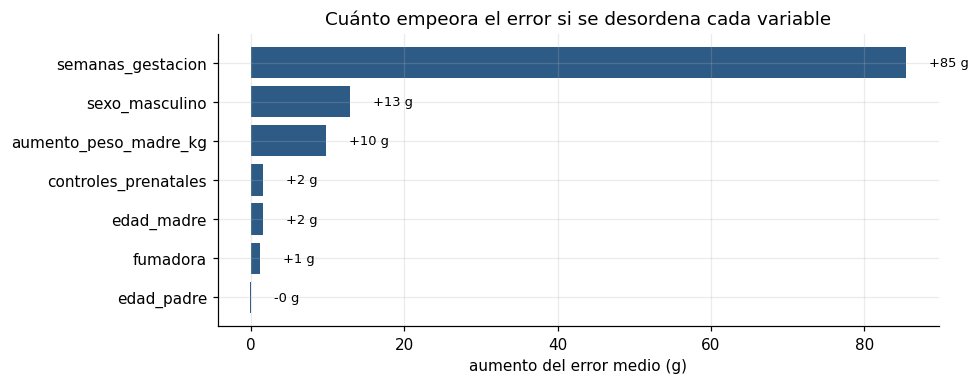

,Explicación
Qué es,La importancia de cada variable: cuánto empeora el error si se desordena al azar.
Qué pregunta responde,¿En qué se fija el modelo para predecir?
Cómo se lee,Barra larga = variable importante. Cerca de 0 = el modelo casi no la usa.
Resultado,La más importante: semanas_gestacion (+85 g). Coincide con lo que dice la medicina.


In [35]:
imp = permutation_importance(regresores["Ridge"], X_pru, yp_pru, scoring="neg_mean_absolute_error",
                             n_repeats=20, random_state=SEMILLA, n_jobs=1)
s = pd.Series(imp.importances_mean, index=ENTRADAS).sort_values()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(s.index, s.values, color=AZUL)
for i, v in enumerate(s.values):
    ax.text(max(v, 0) + 3, i, f"{v:+.0f} g", va="center", fontsize=8.5)
ax.set_title("Cuánto empeora el error si se desordena cada variable"); ax.set_xlabel("aumento del error medio (g)")
plt.tight_layout(); plt.show()

explicar("La importancia de cada variable: cuánto empeora el error si se desordena al azar.",
         "¿En qué se fija el modelo para predecir?",
         "Barra larga = variable importante. Cerca de 0 = el modelo casi no la usa.",
         f"La más importante: {s.idxmax()} (+{s.max():.0f} g). Coincide con lo que dice la medicina.")

### 7.3 Modelo 2 · Clasificación de bajo peso

Para no depender de qué 250 bebés tocaron en la prueba, se evalúa sobre **los 1.000** con
validación cruzada: cada bebé se predice con un modelo que no lo vio, y el umbral se elige en
cada vuelta solo con el entrenamiento de esa vuelta. Se compara con dos reglas simples.

In [36]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
prob_cv = np.zeros(len(df)); alerta_cv = np.zeros(len(df), dtype=int)
for e, p in skf.split(X, y_bajo):
    u = elegir_umbral(X.iloc[e], y_bajo.iloc[e])
    m = clone(clasificador).fit(X.iloc[e], y_bajo.iloc[e])
    prob_cv[p] = m.predict_proba(X.iloc[p])[:, 1]
    alerta_cv[p] = (prob_cv[p] >= u).astype(int)

reglas = {"Modelo 2 (logística + umbral)": alerta_cv,
          "Regla: prematuro (< 37 sem)": (df["semanas_gestacion"] < 37).astype(int).to_numpy(),
          "Curva de Hadlock (< 2.500 g)": (hadlock_total < 2500).astype(int).to_numpy()}
filas = {}
for nombre, pred in reglas.items():
    vn, fp, fn, vp = confusion_matrix(y_bajo, pred, labels=[0, 1]).ravel()
    filas[nombre] = {"VP": vp, "FN": fn, "FP": fp, "VN": vn, "sensibilidad": vp / (vp + fn),
                     "especificidad": vn / (vn + fp), "precisión": vp / (vp + fp) if vp + fp else 0,
                     "F1": f1_score(y_bajo, pred), "exactitud": accuracy_score(y_bajo, pred),
                     "exactitud balanceada": balanced_accuracy_score(y_bajo, pred)}
clasif = pd.DataFrame(filas).T
auc_modelo, auc_sem = roc_auc_score(y_bajo, prob_cv), roc_auc_score(y_bajo, -df["semanas_gestacion"])
ap_modelo = average_precision_score(y_bajo, prob_cv)
print(f"AUC del modelo 2: {auc_modelo:.3f} (solo con las semanas: {auc_sem:.3f}) · precisión media (AP): {ap_modelo:.3f}")
tabla(clasif, rojo=["VP", "FP", "sensibilidad"],
      formato={c: "{:.0f}" for c in ["VP", "FN", "FP", "VN"]}
      | {c: "{:.1%}" for c in ["sensibilidad", "especificidad", "precisión", "F1", "exactitud", "exactitud balanceada"]})

AUC del modelo 2: 0.849 (solo con las semanas: 0.841) · precisión media (AP): 0.515


,VP,FN,FP,VN,sensibilidad,especificidad,precisión,F1,exactitud,exactitud balanceada
Modelo 2 (logística + umbral),73,12,296,619,85.9%,67.7%,19.8%,32.2%,69.2%,76.8%
Regla: prematuro (< 37 sem),55,30,69,846,64.7%,92.5%,44.4%,52.6%,90.1%,78.6%
Curva de Hadlock (< 2.500 g),36,49,23,892,42.4%,97.5%,61.0%,50.0%,92.8%,69.9%


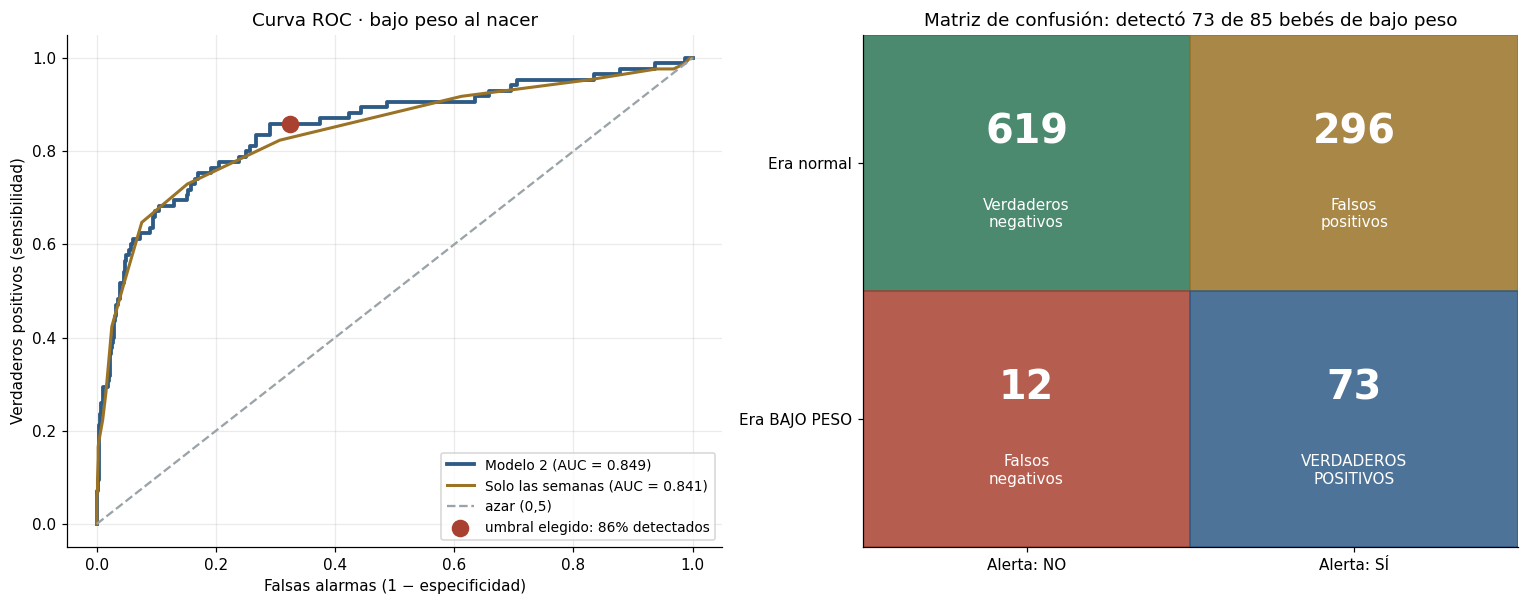

,Explicación
Qué es,Izquierda: la curva ROC. Derecha: la matriz de confusión con el umbral elegido.
Qué pregunta responde,¿Cuántos bebés de bajo peso detecta y a cambio de cuántas falsas alarmas?
Cómo se lee,"ROC: cuanto más arriba a la izquierda, mejor. Matriz: la celda azul son los verdaderos positivos; la ocre, las falsas alarmas; la roja, los que se escaparon."
Resultado,"73 de 85 detectados (86%), 12 se escaparon, 296 falsas alarmas: de cada 100 alertas solo 20 son de verdad. AUC 0.849, casi igual que usar solo las semanas (0.841)."


In [37]:
mm = clasif.loc["Modelo 2 (logística + umbral)"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.6))
fpr, tpr, _ = roc_curve(y_bajo, prob_cv)
a1.plot(fpr, tpr, color=AZUL, lw=2.5, label=f"Modelo 2 (AUC = {auc_modelo:.3f})")
f2, t2, _ = roc_curve(y_bajo, -df["semanas_gestacion"])
a1.plot(f2, t2, color=OCRE, lw=2, label=f"Solo las semanas (AUC = {auc_sem:.3f})")
a1.plot([0, 1], [0, 1], color=GRIS, ls="--", label="azar (0,5)")
a1.scatter(1 - mm["especificidad"], mm["sensibilidad"], s=110, color=ROJO, zorder=5,
           label=f"umbral elegido: {mm['sensibilidad']:.0%} detectados")
a1.set_title("Curva ROC · bajo peso al nacer"); a1.set_xlabel("Falsas alarmas (1 − especificidad)")
a1.set_ylabel("Verdaderos positivos (sensibilidad)"); a1.legend(loc="lower right", fontsize=9)

mc = confusion_matrix(y_bajo, alerta_cv, labels=[0, 1])
etiquetas = [["Verdaderos\nnegativos", "Falsos\npositivos"], ["Falsos\nnegativos", "VERDADEROS\nPOSITIVOS"]]
colores_celda = [[VERDE, OCRE], [ROJO, AZUL]]
a2.grid(False)
for i in range(2):
    for j in range(2):
        a2.add_patch(plt.Rectangle((j, 1 - i), 1, 1, color=colores_celda[i][j], alpha=0.85))
        a2.text(j + 0.5, 1.62 - i, f"{mc[i, j]}", ha="center", va="center", fontsize=26, color="white", fontweight="bold")
        a2.text(j + 0.5, 1.3 - i, etiquetas[i][j], ha="center", va="center", fontsize=10, color="white")
a2.set_xlim(0, 2); a2.set_ylim(0, 2)
a2.set_xticks([0.5, 1.5], ["Alerta: NO", "Alerta: SÍ"]); a2.set_yticks([1.5, 0.5], ["Era normal", "Era BAJO PESO"])
a2.set_title(f"Matriz de confusión: detectó {mc[1, 1]} de {mc[1].sum()} bebés de bajo peso")
plt.tight_layout(); plt.show()

explicar("Izquierda: la curva ROC. Derecha: la matriz de confusión con el umbral elegido.",
         "¿Cuántos bebés de bajo peso detecta y a cambio de cuántas falsas alarmas?",
         "ROC: cuanto más arriba a la izquierda, mejor. Matriz: la celda azul son los verdaderos positivos; "
         "la ocre, las falsas alarmas; la roja, los que se escaparon.",
         f"{int(mm['VP'])} de {int(mm['VP'] + mm['FN'])} detectados ({mm['sensibilidad']:.0%}), {int(mm['FN'])} se escaparon, "
         f"{int(mm['FP'])} falsas alarmas: de cada 100 alertas solo {mm['precisión'] * 100:.0f} son de verdad. AUC {auc_modelo:.3f}, "
         f"casi igual que usar solo las semanas ({auc_sem:.3f}).")

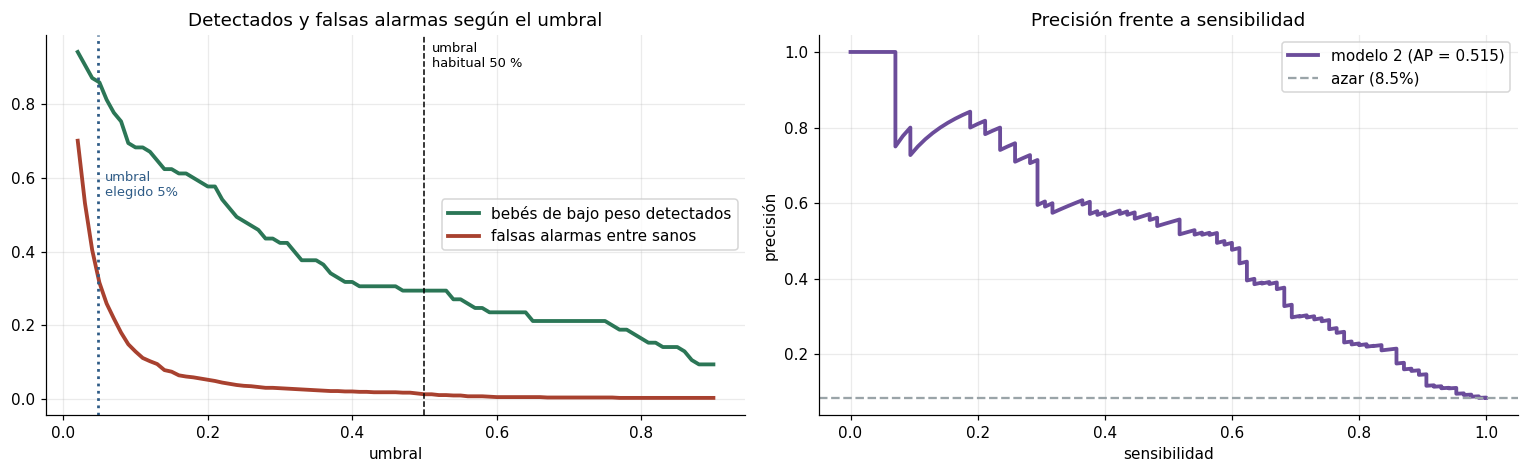

,Explicación
Qué es,Izquierda: cómo cambian los detectados y las falsas alarmas al mover el umbral. Derecha: curva precisión-sensibilidad.
Qué pregunta responde,¿Por qué no se usa el umbral del 50 % y cuánto cuesta detectar más?
Cómo se lee,"Umbral bajo = se detectan más, pero con más falsas alarmas. La curva derecha es más exigente que la ROC cuando la clase es rara."
Resultado,"Con el 50 % se detectaría el 29%; con 5%, el 86%. Precisión media 0.51 frente a 0.09 del azar."


In [38]:
umbrales = np.linspace(0.02, 0.9, 89)
sens = [((prob_cv >= u) & (y_bajo == 1)).sum() / (y_bajo == 1).sum() for u in umbrales]
falsas = [((prob_cv >= u) & (y_bajo == 0)).sum() / (y_bajo == 0).sum() for u in umbrales]
prec, rec, _ = precision_recall_curve(y_bajo, prob_cv)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.4))
a1.plot(umbrales, sens, color=VERDE, lw=2.5, label="bebés de bajo peso detectados")
a1.plot(umbrales, falsas, color=ROJO, lw=2.5, label="falsas alarmas entre sanos")
a1.axvline(umbral, color=AZUL, ls=":", lw=1.8); a1.text(umbral + 0.01, 0.55, f"umbral\nelegido {umbral:.0%}", color=AZUL, fontsize=8.5)
a1.axvline(0.5, color="black", ls="--", lw=1); a1.text(0.51, 0.9, "umbral\nhabitual 50 %", fontsize=8.5)
a1.set_title("Detectados y falsas alarmas según el umbral"); a1.set_xlabel("umbral"); a1.legend(loc="center right")
a2.plot(rec, prec, color=MORADO, lw=2.5, label=f"modelo 2 (AP = {ap_modelo:.3f})")
a2.axhline(y_bajo.mean(), color=GRIS, ls="--", label=f"azar ({y_bajo.mean():.1%})")
a2.set_title("Precisión frente a sensibilidad"); a2.set_xlabel("sensibilidad"); a2.set_ylabel("precisión"); a2.legend()
plt.tight_layout(); plt.show()

explicar("Izquierda: cómo cambian los detectados y las falsas alarmas al mover el umbral. Derecha: curva precisión-sensibilidad.",
         "¿Por qué no se usa el umbral del 50 % y cuánto cuesta detectar más?",
         "Umbral bajo = se detectan más, pero con más falsas alarmas. La curva derecha es más exigente que la ROC cuando la clase es rara.",
         f"Con el 50 % se detectaría el {((prob_cv >= 0.5) & (y_bajo == 1)).sum() / (y_bajo == 1).sum():.0%}; "
         f"con {umbral:.0%}, el {mm['sensibilidad']:.0%}. Precisión media {ap_modelo:.2f} frente a {y_bajo.mean():.2f} del azar.")

### 7.4 Red 3 · Medir la cabeza

In [39]:
real, pred = prueba_hc["circunferencia_cefalica_mm"], prueba_hc["hc_predicha_mm"]
dif_hc = pred - real
sesgo, ds = dif_hc.mean(), dif_hc.std()
r2_hc, mae_hc = r2_score(real, pred), mean_absolute_error(real, pred)
mae_sem = mean_absolute_error(prueba_hc["semanas_real"], prueba_hc["semanas_red"])
met_hc = pd.DataFrame([
    ["R²", f"{r2_hc:.4f}", "Qué parte de la variación de la medida explica la red"],
    ["MAE", f"{mae_hc:.2f} mm", "Error medio"],
    ["Error mediano", f"{dif_hc.abs().median():.2f} mm", "La mitad de las imágenes se equivoca menos"],
    ["RMSE", f"{np.sqrt(mean_squared_error(real, pred)):.2f} mm", "Castiga los errores grandes"],
    ["Dentro de ±10 mm", f"{(dif_hc.abs() <= 10).mean():.1%}", "Imágenes con error pequeño"],
    ["Sesgo (Bland-Altman)", f"{sesgo:+.1f} mm", "Si la red mide de más (+) o de menos (−)"],
    ["Límites de acuerdo 95 %", f"{sesgo - 1.96 * ds:+.0f} a {sesgo + 1.96 * ds:+.0f} mm", "Dónde cae el 95 % de las diferencias"],
    ["Error en semanas", f"{mae_sem:.2f} semanas ({mae_sem * 7:.1f} días)", "Error al fechar el embarazo con Hadlock"],
    ["Imágenes · madres de prueba", f"{len(prueba_hc)} · {prueba_hc['paciente'].nunique()}", "Ninguna vista al entrenar"],
], columns=["Métrica", "Valor", "Qué dice"])
display(tabla(met_hc, rojo=["Valor"], indice=False))
tabla(prueba_hc.assign(err=dif_hc.abs()).groupby("trimestre")["err"].agg(["count", "mean", "median"]).round(2)
      .rename(columns={"count": "imágenes", "mean": "error medio mm", "median": "error mediano mm"}), rojo=["error medio mm"])

Métrica,Valor,Qué dice
R²,0.9780,Qué parte de la variación de la medida explica la red
MAE,6.95 mm,Error medio
Error mediano,5.43 mm,La mitad de las imágenes se equivoca menos
RMSE,9.50 mm,Castiga los errores grandes
Dentro de ±10 mm,79.5%,Imágenes con error pequeño
Sesgo (Bland-Altman),-3.2 mm,Si la red mide de más (+) o de menos (−)
Límites de acuerdo 95 %,-21 a +14 mm,Dónde cae el 95 % de las diferencias
Error en semanas,0.62 semanas (4.3 días),Error al fechar el embarazo con Hadlock
Imágenes · madres de prueba,146 · 117,Ninguna vista al entrenar


,imágenes,error medio mm,error mediano mm
trimestre,,,
primero,19,7.290000,5.610000
segundo,105,6.170000,5.190000
tercero,22,10.400000,7.380000


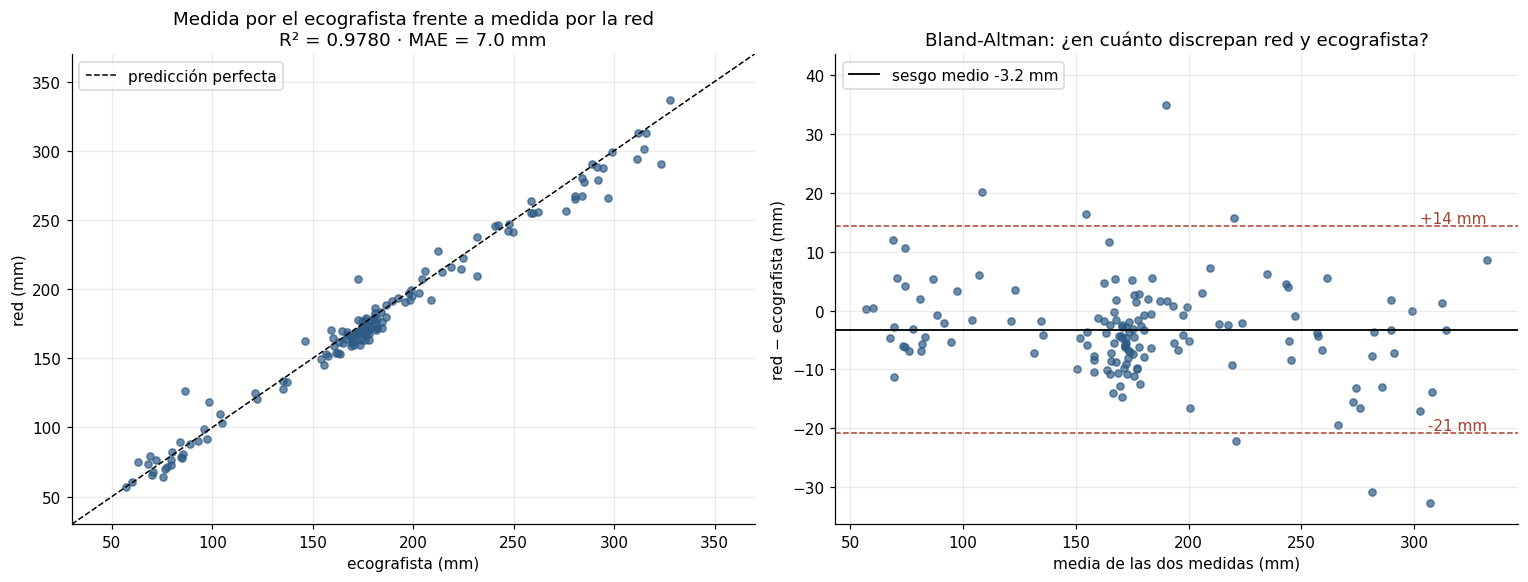

,Explicación
Qué es,"Izquierda: cada imagen de prueba, medida por el ecografista y por la red. Derecha: Bland-Altman."
Qué pregunta responde,¿Mide la red como un profesional? ¿En cuánto puede discrepar en una imagen concreta?
Cómo se lee,Izquierda: pegado a la diagonal = acierta. Derecha: las líneas rojas encierran el 95 % de las diferencias.
Resultado,R² REAL = 0.9780 sobre 146 imágenes de madres no vistas. Error medio 7.0 mm (4 días de embarazo). Los mejores métodos publicados llegan a ~2 mm dibujando la elipse.


In [40]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.4))
a1.scatter(real, pred, s=22, alpha=0.7, color=AZUL)
a1.plot([30, 370], [30, 370], "k--", lw=1, label="predicción perfecta")
a1.set_xlim(30, 370); a1.set_ylim(30, 370)
a1.set_title(f"Medida por el ecografista frente a medida por la red\nR² = {r2_hc:.4f} · MAE = {mae_hc:.1f} mm")
a1.set_xlabel("ecografista (mm)"); a1.set_ylabel("red (mm)"); a1.legend()
media_par = (real + pred) / 2
a2.scatter(media_par, dif_hc, s=22, alpha=0.7, color=AZUL)
a2.axhline(sesgo, color="black", lw=1.2, label=f"sesgo medio {sesgo:+.1f} mm")
for lim_ in (sesgo - 1.96 * ds, sesgo + 1.96 * ds):
    a2.axhline(lim_, color=ROJO, ls="--", lw=1)
    a2.text(media_par.max(), lim_, f" {lim_:+.0f} mm", color=ROJO, va="bottom", ha="right")
a2.set_title("Bland-Altman: ¿en cuánto discrepan red y ecografista?")
a2.set_xlabel("media de las dos medidas (mm)"); a2.set_ylabel("red − ecografista (mm)"); a2.legend(loc="upper left")
plt.tight_layout(); plt.show()

explicar("Izquierda: cada imagen de prueba, medida por el ecografista y por la red. Derecha: Bland-Altman.",
         "¿Mide la red como un profesional? ¿En cuánto puede discrepar en una imagen concreta?",
         "Izquierda: pegado a la diagonal = acierta. Derecha: las líneas rojas encierran el 95 % de las diferencias.",
         f"R² REAL = {r2_hc:.4f} sobre {len(prueba_hc)} imágenes de madres no vistas. Error medio {mae_hc:.1f} mm "
         f"({mae_sem * 7:.0f} días de embarazo). Los mejores métodos publicados llegan a ~2 mm dibujando la elipse.")

### 7.5 Red 4 · Reconocer el plano

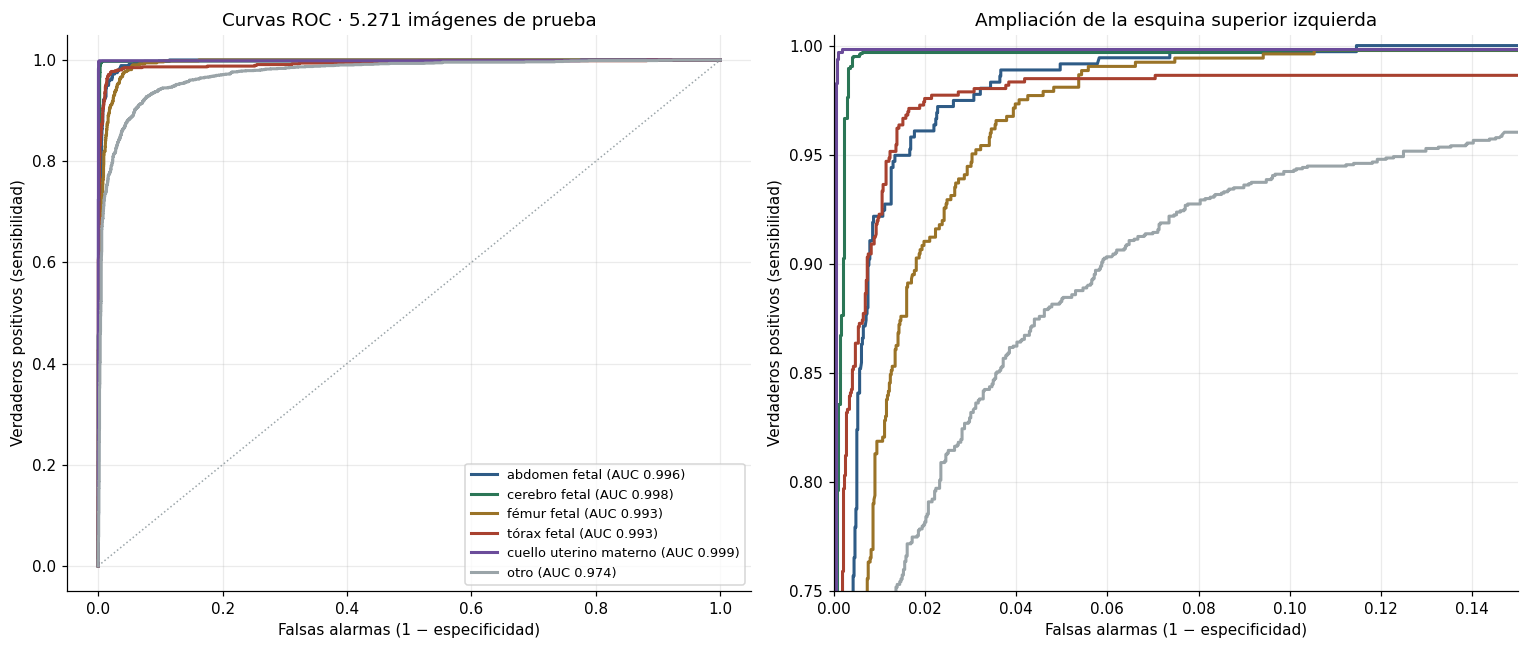

,Explicación
Qué es,Una curva ROC por plano: verdaderos positivos frente a falsas alarmas.
Qué pregunta responde,¿Separa la red cada plano de los demás?
Cómo se lee,"Cuanto más pegada a la esquina de arriba a la izquierda, mejor. AUC 1 = perfecto, 0,5 = azar."
Resultado,AUC de 0.974 («otro») a 0.999 («cuello uterino materno»). Media 0.992.


In [41]:
y_real, y_pred = prueba_planos["plano"], prueba_planos["plano_predicho"]
colores_plano = [AZUL, VERDE, OCRE, ROJO, MORADO, GRIS]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6))
aucs = {}
for plano, color in zip(cnn.PLANOS, colores_plano):
    verdad = (y_real == plano).astype(int)
    fpr, tpr, _ = roc_curve(verdad, prueba_planos[f"prob_{plano}"])
    aucs[plano] = roc_auc_score(verdad, prueba_planos[f"prob_{plano}"])
    for ax in (a1, a2):
        ax.plot(fpr, tpr, color=color, lw=2, label=f"{plano} (AUC {aucs[plano]:.3f})")
for ax in (a1, a2):
    ax.plot([0, 1], [0, 1], color=GRIS, ls=":", lw=1)
    ax.set_xlabel("Falsas alarmas (1 − especificidad)"); ax.set_ylabel("Verdaderos positivos (sensibilidad)")
a1.set_title(f"Curvas ROC · {miles(len(prueba_planos))} imágenes de prueba"); a1.legend(loc="lower right", fontsize=8.5)
a2.set_xlim(0, 0.15); a2.set_ylim(0.75, 1.005); a2.set_title("Ampliación de la esquina superior izquierda")
plt.tight_layout(); plt.show()

explicar("Una curva ROC por plano: verdaderos positivos frente a falsas alarmas.",
         "¿Separa la red cada plano de los demás?",
         "Cuanto más pegada a la esquina de arriba a la izquierda, mejor. AUC 1 = perfecto, 0,5 = azar.",
         f"AUC de {min(aucs.values()):.3f} («{min(aucs, key=aucs.get)}») a {max(aucs.values()):.3f} "
         f"(«{max(aucs, key=aucs.get)}»). Media {np.mean(list(aucs.values())):.3f}.")

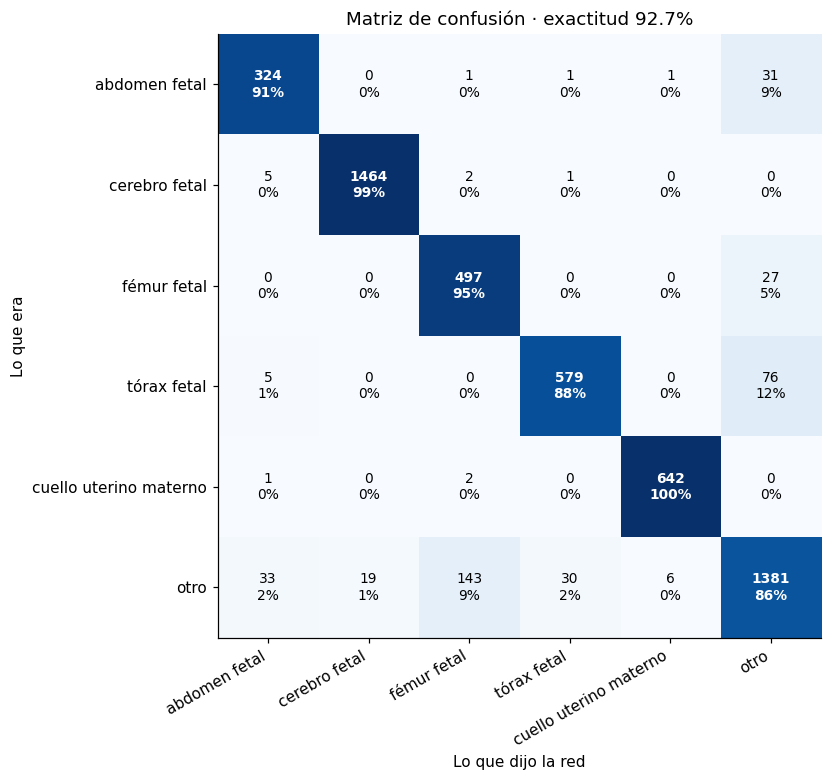

,Explicación
Qué es,"La matriz de confusión: cada fila es lo que era la imagen; cada columna, lo que dijo la red."
Qué pregunta responde,¿En qué planos acierta y con cuáles se confunde?
Cómo se lee,"La diagonal son los verdaderos positivos. Fuera de la diagonal, los errores."
Resultado,"4.887 de 5.271 bien (92.7%). Casi todos los errores van hacia o desde «otro», la clase cajón de sastre."


In [42]:
mc4 = confusion_matrix(y_real, y_pred, labels=cnn.PLANOS)
fig, ax = plt.subplots(figsize=(9, 7.2))
ax.imshow(mc4 / mc4.sum(axis=1, keepdims=True), cmap="Blues"); ax.grid(False)
for i in range(6):
    for j in range(6):
        v = mc4[i, j] / mc4[i].sum()
        ax.text(j, i, f"{mc4[i, j]}\n{v:.0%}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.5 else "black", fontweight="bold" if i == j else "normal")
ax.set_xticks(range(6), cnn.PLANOS, rotation=30, ha="right"); ax.set_yticks(range(6), cnn.PLANOS)
ax.set_xlabel("Lo que dijo la red"); ax.set_ylabel("Lo que era")
ax.set_title(f"Matriz de confusión · exactitud {accuracy_score(y_real, y_pred):.1%}")
plt.tight_layout(); plt.show()

explicar("La matriz de confusión: cada fila es lo que era la imagen; cada columna, lo que dijo la red.",
         "¿En qué planos acierta y con cuáles se confunde?",
         "La diagonal son los verdaderos positivos. Fuera de la diagonal, los errores.",
         f"{miles(np.diag(mc4).sum())} de {miles(mc4.sum())} bien ({np.diag(mc4).sum() / mc4.sum():.1%}). "
         "Casi todos los errores van hacia o desde «otro», la clase cajón de sastre.")

In [43]:
vp4, fn4, fp4 = np.diag(mc4), mc4.sum(axis=1) - np.diag(mc4), mc4.sum(axis=0) - np.diag(mc4)
por_plano = pd.DataFrame({
    "imágenes": mc4.sum(axis=1), "VP": vp4, "FN (se escaparon)": fn4, "FP (falsas alarmas)": fp4,
    "sensibilidad": vp4 / (vp4 + fn4), "precisión": vp4 / (vp4 + fp4),
    "F1": 2 * vp4 / (2 * vp4 + fn4 + fp4), "AUC": [aucs[p] for p in cnn.PLANOS]}, index=cnn.PLANOS)
display(tabla(por_plano, rojo=["VP", "FP (falsas alarmas)"],
              formato={"sensibilidad": "{:.1%}", "precisión": "{:.1%}", "F1": "{:.3f}", "AUC": "{:.4f}"}))
glob4 = pd.DataFrame([
    ["Exactitud", f"{accuracy_score(y_real, y_pred):.1%}", "Imágenes bien reconocidas"],
    ["Exactitud balanceada", f"{balanced_accuracy_score(y_real, y_pred):.1%}", "Media de la sensibilidad de los 6 planos"],
    ["F1 macro", f"{f1_score(y_real, y_pred, average='macro'):.3f}", "Equilibrio sensibilidad-precisión, media de los 6"],
    ["Kappa de Cohen", f"{cohen_kappa_score(y_real, y_pred):.3f}", "Acierto por encima del azar (1 = perfecto)"],
    ["AUC medio", f"{np.mean(list(aucs.values())):.4f}", "Separación media de los 6 planos"],
    ["Imágenes · madres de prueba", f"{miles(len(prueba_planos))} · {miles(prueba_planos['paciente'].nunique())}", "Ninguna vista al entrenar"],
], columns=["Métrica", "Valor", "Qué dice"])
tabla(glob4, rojo=["Valor"], indice=False)

,imágenes,VP,FN (se escaparon),FP (falsas alarmas),sensibilidad,precisión,F1,AUC
abdomen fetal,358,324,34,44,90.5%,88.0%,0.893,0.9956
cerebro fetal,1472,1464,8,19,99.5%,98.7%,0.991,0.9980
fémur fetal,524,497,27,148,94.8%,77.1%,0.850,0.9929
tórax fetal,660,579,81,32,87.7%,94.8%,0.911,0.9925
cuello uterino materno,645,642,3,7,99.5%,98.9%,0.992,0.9986
otro,1612,1381,231,134,85.7%,91.2%,0.883,0.9741


Métrica,Valor,Qué dice
Exactitud,92.7%,Imágenes bien reconocidas
Exactitud balanceada,93.0%,Media de la sensibilidad de los 6 planos
F1 macro,0.920,"Equilibrio sensibilidad-precisión, media de los 6"
Kappa de Cohen,0.907,Acierto por encima del azar (1 = perfecto)
AUC medio,0.9920,Separación media de los 6 planos
Imágenes · madres de prueba,5.271 · 896,Ninguna vista al entrenar


### 7.6 ¿Y si fuera un modelo NO supervisado?

Para responder qué haría un modelo no supervisado, se prueba **K-means**, el más conocido:
agrupa casos parecidos **sin ver la respuesta**. Las respuestas solo se usan **después**,
para ver si los grupos que encontró tienen algo que ver con lo que queremos saber.

In [44]:
# A) Nacimientos: 2 grupos con las 7 variables, sin mirar el peso
Xn = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit_transform(X)
grupos_nac = KMeans(2, n_init=10, random_state=SEMILLA).fit_predict(Xn)
ct_nac = pd.crosstab(grupos_nac, y_bajo.map({0: "peso normal", 1: "bajo peso"}))
ct_nac["% bajo peso"] = (ct_nac["bajo peso"] / ct_nac.sum(axis=1) * 100).round(1)
ct_nac.index = [f"grupo {g + 1}" for g in ct_nac.index]

# B) Imágenes de prueba: 6 grupos con rasgos de una red que NUNCA vio una etiqueta de ecografía
rasgos = cnn.rasgos_imagenet([Path(r) for r in prueba_planos["ruta"]])
grupos_img = KMeans(6, n_init=10, random_state=SEMILLA).fit_predict(StandardScaler().fit_transform(rasgos))
ct_img = pd.crosstab(pd.Series(grupos_img, name="grupo"), y_real.rename("plano real"))
# Si a cada grupo se le pone el nombre del plano que más tiene, ¿cuántas acertaría?
exact_nosup = ct_img.max(axis=1).sum() / len(y_real)
ari = adjusted_rand_score(y_real, grupos_img)
ct_img.index = [f"grupo {g + 1}" for g in ct_img.index]

display(tabla(ct_nac, rojo=["% bajo peso"]))
display(tabla(ct_img))
tabla(pd.DataFrame([
    ["Nacimientos → bajo peso", "K-means, 2 grupos", "Grupos de madres parecidas",
     f"% de bajo peso por grupo: {' y '.join(f'{v:.0f} %' for v in ct_nac['% bajo peso'])}",
     f"Modelo 2 supervisado: detecta {clasif.loc['Modelo 2 (logística + umbral)', 'sensibilidad']:.0%}"],
    ["Imágenes → plano", "K-means, 6 grupos", "Grupos de imágenes parecidas",
     f"{exact_nosup:.1%} si cada grupo se llama como su plano mayoritario (ARI {ari:.2f})",
     f"Red 4 supervisada: {accuracy_score(y_real, y_pred):.1%}"],
], columns=["Problema", "No supervisado", "Qué entrega", "Resultado", "Supervisado, para comparar"]),
      rojo=["Resultado", "Supervisado, para comparar"], indice=False)

bajo_peso,bajo peso,peso normal,% bajo peso
grupo 1,43,407,9.600000
grupo 2,42,508,7.600000


plano real,abdomen fetal,cerebro fetal,cuello uterino materno,fémur fetal,otro,tórax fetal
grupo 1,113,558,5,62,181,181
grupo 2,95,437,4,90,221,22
grupo 3,13,15,0,6,367,348
grupo 4,113,373,2,351,349,102
grupo 5,0,0,623,0,10,0
grupo 6,24,89,11,15,484,7


Problema,No supervisado,Qué entrega,Resultado,"Supervisado, para comparar"
Nacimientos → bajo peso,"K-means, 2 grupos",Grupos de madres parecidas,% de bajo peso por grupo: 10 % y 8 %,Modelo 2 supervisado: detecta 86%
Imágenes → plano,"K-means, 6 grupos",Grupos de imágenes parecidas,53.9% si cada grupo se llama como su plano mayoritario (ARI 0.19),Red 4 supervisada: 92.7%


In [45]:
explicar("Un modelo NO supervisado (K-means) aplicado a los mismos datos, sin ver las respuestas.",
         "¿Podría un modelo no supervisado hacer lo mismo que los supervisados?",
         "Si los grupos coincidieran con las respuestas, cada grupo tendría casi solo una clase. ARI = 1 sería "
         "coincidencia perfecta; 0, ninguna.",
         f"No. Con las imágenes acierta como mucho el {exact_nosup:.0%} (la red supervisada, "
         f"{accuracy_score(y_real, y_pred):.0%}), y con los nacimientos no separa el bajo peso. Además no da "
         "gramos ni milímetros: solo agrupa. Por eso el proyecto usa aprendizaje supervisado.")

,Explicación
Qué es,"Un modelo NO supervisado (K-means) aplicado a los mismos datos, sin ver las respuestas."
Qué pregunta responde,¿Podría un modelo no supervisado hacer lo mismo que los supervisados?
Cómo se lee,"Si los grupos coincidieran con las respuestas, cada grupo tendría casi solo una clase. ARI = 1 sería coincidencia perfecta; 0, ninguna."
Resultado,"No. Con las imágenes acierta como mucho el 54% (la red supervisada, 93%), y con los nacimientos no separa el bajo peso. Además no da gramos ni milímetros: solo agrupa. Por eso el proyecto usa aprendizaje supervisado."


### 7.7 Revisión de errores: ¿hay fugas, trampas o falsos positivos escondidos?

Cada fila es una comprobación que hace el propio notebook. Si alguna fallara, saldría **FALLA**.

In [46]:
def estado(ok):
    return "OK" if ok else "FALLA"

r2_manual_peso = 1 - ((yp_pru - pred_peso[mejor]) ** 2).sum() / ((yp_pru - yp_pru.mean()) ** 2).sum()
r2_manual_hc = 1 - ((real - pred) ** 2).sum() / ((real - real.mean()) ** 2).sum()
prohibidas = {"peso_nacimiento_g", "bajo_peso", "prematuro"} & set(ENTRADAS)
revision = pd.DataFrame([
    ["Madres compartidas entre entrenamiento y prueba (imágenes)", int(solapes["entrenamiento Y prueba"].sum()),
     estado(solapes["entrenamiento Y prueba"].sum() == 0), "Si una madre estuviera en los dos lados, el resultado se inflaría"],
    ["Madres compartidas entre validación y prueba", int(solapes["validación Y prueba"].sum()),
     estado(solapes["validación Y prueba"].sum() == 0), "La época se elige con validación: no puede tocar la prueba"],
    ["Respuestas usadas como entrada (modelos 1 y 2)", ", ".join(prohibidas) or "ninguna",
     estado(not prohibidas), "Meter el peso o «prematuro» como entrada sería copiar la respuesta"],
    ["Umbral del modelo 2 elegido sin mirar la prueba", "sí: validación cruzada del entrenamiento", "OK",
     "Elegirlo con la prueba daría una sensibilidad falsa"],
    ["R² del modelo 1 recalculado a mano", f"{r2_manual_peso:.4f} = {r2_score(yp_pru, pred_peso[mejor]):.4f}",
     estado(abs(r2_manual_peso - r2_score(yp_pru, pred_peso[mejor])) < 1e-9), "1 − Σ(real − previsto)² / Σ(real − media)²"],
    ["R² de la red 3 recalculado a mano", f"{r2_manual_hc:.4f} = {r2_hc:.4f}",
     estado(abs(r2_manual_hc - r2_hc) < 1e-9), "El mismo cálculo, sobre las imágenes de prueba"],
    ["Falsos positivos del modelo 2 declarados", int(mm["FP"]), "OK",
     f"De cada 100 alertas, {100 - mm['precisión'] * 100:.0f} son falsas alarmas: está dicho, no escondido"],
    ["Falsos positivos de la red 4 declarados", int(fp4.sum()), "OK",
     f"El más frecuente: «{por_plano['FP (falsas alarmas)'].idxmax()}» ({int(por_plano['FP (falsas alarmas)'].max())})"],
    ["Clasificación medida con la clase rara", f"sensibilidad {mm['sensibilidad']:.0%}, no solo exactitud", "OK",
     f"Decir siempre «normal» daría {1 - y_bajo.mean():.1%} de exactitud y 0 detectados"],
], columns=["Comprobación", "Valor", "Estado", "Por qué importa"])
tabla(revision, rojo=["Estado"], indice=False)

Comprobación,Valor,Estado,Por qué importa
Madres compartidas entre entrenamiento y prueba (imágenes),0,OK,"Si una madre estuviera en los dos lados, el resultado se inflaría"
Madres compartidas entre validación y prueba,0,OK,La época se elige con validación: no puede tocar la prueba
Respuestas usadas como entrada (modelos 1 y 2),ninguna,OK,Meter el peso o «prematuro» como entrada sería copiar la respuesta
Umbral del modelo 2 elegido sin mirar la prueba,sí: validación cruzada del entrenamiento,OK,Elegirlo con la prueba daría una sensibilidad falsa
R² del modelo 1 recalculado a mano,0.3224 = 0.3224,OK,1 − Σ(real − previsto)² / Σ(real − media)²
R² de la red 3 recalculado a mano,0.9780 = 0.9780,OK,"El mismo cálculo, sobre las imágenes de prueba"
Falsos positivos del modelo 2 declarados,296,OK,"De cada 100 alertas, 80 son falsas alarmas: está dicho, no escondido"
Falsos positivos de la red 4 declarados,384,OK,El más frecuente: «fémur fetal» (148)
Clasificación medida con la clase rara,"sensibilidad 86%, no solo exactitud",OK,Decir siempre «normal» daría 91.5% de exactitud y 0 detectados


### 7.8 Resumen de todos los modelos

In [47]:
resumen = pd.DataFrame([
    ["1. Peso al nacer", "Regresión", "1.000 nacimientos reales", "R² (prueba)", f"{r2_score(yp_pru, pred_peso[mejor]):.3f}",
     f"MAE {cv.loc[mejor, 'MAE medio (g)']:.0f} g · frente a Hadlock: {veredicto} ({dif.mean():+.0f} g)",
     "Como apoyo, al lado de Hadlock" if mejora_real else "No: no mejora a Hadlock"],
    ["2. Bajo peso", "Clasificación", "1.000 nacimientos reales", "Verdaderos positivos",
     f"{int(mm['VP'])} de {int(mm['VP'] + mm['FN'])} ({mm['sensibilidad']:.0%})",
     f"{int(mm['FP'])} falsas alarmas · AUC {auc_modelo:.3f}", "Como alerta de apoyo"],
    ["3. Red: cabeza", "Regresión (CNN)", "999 ecografías reales", "R² (prueba)", f"{r2_hc:.4f}",
     f"MAE {mae_hc:.1f} mm · {mae_sem * 7:.0f} días", "Sí, en el sistema"],
    ["4. Red: plano", "Clasificación (CNN)", "12.400 ecografías reales", "Exactitud",
     f"{accuracy_score(y_real, y_pred):.1%}", f"{miles(np.diag(mc4).sum())} VP de {miles(mc4.sum())} · AUC {np.mean(list(aucs.values())):.3f}",
     "Sí, en el sistema"],
], columns=["Modelo", "Tipo", "Datos", "Métrica principal", "Resultado REAL", "Además", "¿Listo para usar?"])
tabla(resumen, rojo=["Resultado REAL"], indice=False)

Modelo,Tipo,Datos,Métrica principal,Resultado REAL,Además,¿Listo para usar?
1. Peso al nacer,Regresión,1.000 nacimientos reales,R² (prueba),0.322,MAE 374 g · frente a Hadlock: MEJORA REAL (+21 g),"Como apoyo, al lado de Hadlock"
2. Bajo peso,Clasificación,1.000 nacimientos reales,Verdaderos positivos,73 de 85 (86%),296 falsas alarmas · AUC 0.849,Como alerta de apoyo
3. Red: cabeza,Regresión (CNN),999 ecografías reales,R² (prueba),0.9780,MAE 7.0 mm · 4 días,"Sí, en el sistema"
4. Red: plano,Clasificación (CNN),12.400 ecografías reales,Exactitud,92.7%,4.887 VP de 5.271 · AUC 0.992,"Sí, en el sistema"


**Por qué el R² del peso al nacer es bajo y el de la cabeza es alto — y los dos son reales:**
el peso al nacer se predice **sin ecografía**, solo con las semanas y datos de la madre, y dos
bebés de la misma semana pueden pesar 1.500 g de diferencia. La cabeza, en cambio, **se ve**
en la imagen: la red mide algo que está ahí. Subir el R² del peso exigiría añadir las medidas
de la ecografía, que es justo lo que hacen las redes.

### 7.9 Dónde está en el sistema y cuándo usarlo

In [48]:
tabla(pd.DataFrame([
    ["Este notebook, imágenes y catálogo", "historial/datos_ecografia_reales/"],
    ["Nacimientos reales (modelos 1 y 2)", "historial/modelo_peso_nacimiento/datos/"],
    ["Redes guardadas", "datos_ecografia_reales/modelos/ → copiadas a Backend/Microservicio_IA/trained_models/"],
    ["Servicio de IA (redes 3 y 4)", "Backend/Microservicio_IA/app/ecografia_real.py · POST /api/plano-anatomico · POST /api/biometria/circunferencia-cefalica"],
    ["Backend Django", "POST /api/ecografias/plano-anatomico/ · POST /api/ecografias/circunferencia-cefalica/"],
    ["Pantalla", "IA Médica → Análisis CNN → tarjeta «Redes entrenadas con ecografías reales»"],
    ["Modelo de peso dentro del sistema", "Backend/ia_medica/ml/ · comandos construir_dataset_peso y entrenar_modelo_peso"],
    ["Fórmulas de Hadlock", "Backend/ecografias/peso_fetal.py"],
], columns=["Pieza", "Dónde"]), rojo=["Dónde"], indice=False)

Pieza,Dónde
"Este notebook, imágenes y catálogo",historial/datos_ecografia_reales/
Nacimientos reales (modelos 1 y 2),historial/modelo_peso_nacimiento/datos/
Redes guardadas,datos_ecografia_reales/modelos/ → copiadas a Backend/Microservicio_IA/trained_models/
Servicio de IA (redes 3 y 4),Backend/Microservicio_IA/app/ecografia_real.py · POST /api/plano-anatomico · POST /api/biometria/circunferencia-cefalica
Backend Django,POST /api/ecografias/plano-anatomico/ · POST /api/ecografias/circunferencia-cefalica/
Pantalla,IA Médica → Análisis CNN → tarjeta «Redes entrenadas con ecografías reales»
Modelo de peso dentro del sistema,Backend/ia_medica/ml/ · comandos construir_dataset_peso y entrenar_modelo_peso
Fórmulas de Hadlock,Backend/ecografias/peso_fetal.py


**Cuándo usarlo con pacientes:** las imágenes son de Países Bajos y Barcelona, y los
nacimientos de EE. UU. Antes de usarlo en Bolivia hay que comprobarlo con ecografías y partos
de aquí (unas 100 ecografías medidas por un ecografista y unos 300 partos). El sistema ya
tiene lo necesario para repetir estas mismas mediciones. **Es apoyo a la decisión, no un
diagnóstico.**